# Floor 6 — 2018 vs 2019 Comparative Analysis

**Dataset:** CU-BEMS Smart Building Energy & Indoor Environmental Data (Kaggle)
**Files analysed:** `data/2018Floor6.csv` and `data/2019Floor6.csv`
**Scope:** one floor (Floor 6), 5 zones, 1-minute sampling, power + indoor-environment sensors.

This notebook compares **what changed on Floor 6 between 2018 and 2019**: how much energy
was consumed, *when* it was consumed (load profiles, weekday/weekend, occupied/after-hours),
how the zones and end-uses (cooling / lighting / plug loads) differ, how the indoor climate
sensors behaved, and which days are statistically unusual.

---

## ⚠️ Read this first — data coverage caveats

The two years are **not** symmetrical, so every year-on-year number below has to be read with
these facts in mind:

| | 2018 file | 2019 file |
|---|---|---|
| Rows read | 264,960 | 424,169 (last row corrupt) |
| Valid period | **1 Jul 00:00 → 31 Dec 23:59** (184 days, complete) | **1 Jan 00:00 → 22 Oct 13:27** (295 days, then file ends) |
| Missing Nov–Dec | — | **no data at all for Nov & Dec 2019** |
| Power (kW) columns | ~0.1–0.8 % missing | ~0.1–0.2 % missing |
| Environment sensors (°C / RH / lux) | **~61 % missing** — all four sensors die in mid-Sep 2018 and never come back | **23–31 % missing** — dead 1 Jan–6 Mar and again 1–22 Oct 2019 |
| Corrupt rows | none | final row has `Date = "2"` → must be dropped |

**Consequences handled in this notebook:**

1. **Raw totals are not comparable** → the year-on-year section compares *only the months both
   years actually have (Jul–Oct)* and also reports **kWh per day** so partial months/years are fair.
2. **Environmental analysis is restricted to windows where the sensors were alive** → coverage is
   measured first, then monthly means are masked below a 50 % coverage threshold.
3. **Power data is of high quality** → energy and load-profile conclusions are robust.

## Column guide

Each CSV has a `Date` timestamp column plus 29 measurement columns named
`<zone>_<channel>(<unit>)`:

| Zone | AC (cooling) channels | Lighting | Plug | Environment sensor (degC / RH% / lux) |
|---|---|---|---|---|
| z1 | AC1 | ✔ | ✔ | ✔ |
| z2 | AC1 | ✔ | ✔ | ✔ |
| z3 | **none** | ✔ | ✔ | **none** |
| z4 | AC1, AC2, AC3, AC4 | ✔ | ✔ | ✔ |
| z5 | AC1 | ✔ | ✔ | ✔ |

* **Power columns are in kW sampled every minute** → energy in kWh = `kW / 60`, summed over rows.
* **Zone 3 has no AC and no sensors** — it is a lighting + plug-only zone, which is why its
  consumption is an order of magnitude smaller than the others.

## Notebook map

1. Setup → 2. Load & inspect → 3. Data quality (the important one) → 4. Time features →
5. Energy derivation → 6. Yearly comparison → 7. Monthly year-on-year → 8. Load profiles →
9. Peak / base / load factor → 10. Indoor environment → 11. Correlations →
12. Anomaly detection → 13. Findings

## 1. Setup

Imports the three libraries this project uses (`pandas` for all tabular work, `numpy` for
numeric helpers, `matplotlib` for charts), sets display options so tables are readable, and
locates the `data/` folder. The path check works whether the notebook is launched from
`workspace/` (normal VS Code / Jupyter case) or from the repo root.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# --- display options -------------------------------------------------------
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 170)
plt.rcParams['figure.figsize'] = (12, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# --- locate the data folder ------------------------------------------------
DATA_DIR = next(p for p in [Path('../data'), Path('data')] if p.exists())
print('Using data folder:', DATA_DIR.resolve())

FILE_2018 = DATA_DIR / '2018Floor6.csv'
FILE_2019 = DATA_DIR / '2019Floor6.csv'

Using data folder: C:\Users\Willi\Documents\Y3S1\SBA\Project\is4001-g1-smart-building\data


## 2. Load & inspect

Read each CSV **as-is first** (before any cleaning) so we can see exactly what we were handed:
shape, column list, data types and a numeric summary. `pd.read_csv` is the only loader needed —
both files have an identical 30-column layout, which is asserted below so that any future
re-download that changes the schema is caught immediately.

In [2]:
raw18 = pd.read_csv(FILE_2018)
raw19 = pd.read_csv(FILE_2019)

print(f'2018 file : {raw18.shape[0]:,} rows x {raw18.shape[1]} columns')
print(f'2019 file : {raw19.shape[0]:,} rows x {raw19.shape[1]} columns')
print('Identical column layout in both years:', list(raw18.columns) == list(raw19.columns))

raw18.head(3)

2018 file : 264,960 rows x 30 columns
2019 file : 424,169 rows x 30 columns
Identical column layout in both years: True


,Date,z1_AC1(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z4_AC1(kW),z4_AC2(kW),z4_AC3(kW),z4_AC4(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux)
0,2018-07-01 00:00:00,0.0,0.0,0.31,27.57,72.19,0.0,0.0,0.01,0.13,27.79,70.56,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.07,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.48,0.0
1,2018-07-01 00:01:00,0.0,0.0,0.31,27.57,72.18,0.0,0.0,0.01,0.13,27.78,70.56,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.06,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.48,0.0
2,2018-07-01 00:02:00,0.0,0.0,0.31,27.57,72.18,0.0,0.0,0.01,0.13,27.77,70.56,0.0,0.02,0.27,0.0,0.0,0.0,0.0,0.0,0.11,27.28,71.76,0.0,0.0,0.0,0.01,28.9,68.50,0.0


In [3]:
# Data types + numeric summary of the raw 2018 file (2019 is identical in structure).
# .T transposes so each column becomes a row — far easier to read with 29 measurements.
dtype_table = pd.DataFrame({
    '2018 dtype': raw18.dtypes.astype(str),
    '2019 dtype': raw19.dtypes.astype(str),
})
print('All dtypes identical across years:',
      (dtype_table['2018 dtype'] == dtype_table['2019 dtype']).all())
display(dtype_table.T)

raw18.describe().T

All dtypes identical across years: True


,Date,z1_AC1(kW),z1_Light(kW),z1_Plug(kW),z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_AC1(kW),z2_Light(kW),z2_Plug(kW),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_Light(kW),z3_Plug(kW),z4_AC1(kW),z4_AC2(kW),z4_AC3(kW),z4_AC4(kW),z4_Light(kW),z4_Plug(kW),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_AC1(kW),z5_Light(kW),z5_Plug(kW),z5_S1(degC),z5_S1(RH%),z5_S1(lux)
2018 dtype,object,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
2019 dtype,object,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


,count,mean,std,min,25%,50%,75%,max
z1_AC1(kW),264487.0,3.931651,7.867317,0.00,0.00,0.00,0.00,50.99
z1_Light(kW),264458.0,1.339641,1.638656,0.00,0.00,0.00,3.33,18.35
z1_Plug(kW),264428.0,0.469952,0.399244,0.00,0.20,0.28,0.70,6.10
z1_S1(degC),101122.0,27.216461,1.528604,22.55,26.68,27.43,28.21,31.90
z1_S1(RH%),101122.0,60.980537,5.638611,46.85,56.98,61.53,65.19,74.90
z1_S1(lux),101122.0,18.232966,22.593602,0.00,0.00,1.00,47.00,59.00
z2_AC1(kW),264486.0,3.450210,7.122975,0.00,0.00,0.00,0.00,58.41
z2_Light(kW),264458.0,2.786105,2.976667,0.00,0.01,1.38,6.08,32.48
z2_Plug(kW),264526.0,0.385526,0.439753,0.00,0.12,0.15,0.65,9.39
z2_S1(degC),103434.0,26.358444,1.875869,21.71,25.91,26.74,27.50,32.70


### 2.1 Turn the column names into metadata

Column names carry the structure `zone_channel(unit)` (e.g. `z4_AC2(kW)`).
`Series.str.extract` pulls those three pieces out with a regular expression, and the result is
used everywhere else in the notebook to build column lists automatically (all power columns, all
AC columns, all temperature columns, …) instead of hard-coding 29 names by hand.

**Why it matters:** the pivot table underneath is a quick audit of the floor — it shows at a
glance that Zone 3 has no AC and no sensor, and that Zone 4 has four AC units.

In [4]:
col_meta = pd.DataFrame({'column': raw18.columns[1:]})          # skip 'Date'
col_meta = pd.concat([
    col_meta,
    col_meta['column'].str.extract(r'^(?P<zone>z\d+)_(?P<channel>.+?)\((?P<unit>.+)\)$'),
], axis=1)

# classify: power measurement vs environment sensor, and end-use
col_meta['kind'] = np.where(col_meta['unit'] == 'kW', 'power', 'sensor')
col_meta['end_use'] = col_meta['channel'].map(
    lambda c: 'Cooling (AC)' if c.startswith('AC')
    else ('Lighting' if c == 'Light' else ('Plug load' if c == 'Plug' else 'Sensor'))
)

display(col_meta)

# Number of channels per zone / end-use  -> the floor-layout audit table
col_meta.pivot_table(index='zone', columns='end_use', values='column',
                     aggfunc='count', fill_value=0)

,column,zone,channel,unit,kind,end_use
0,z1_AC1(kW),z1,AC1,kW,power,Cooling (AC)
1,z1_Light(kW),z1,Light,kW,power,Lighting
2,z1_Plug(kW),z1,Plug,kW,power,Plug load
3,z1_S1(degC),z1,S1,degC,sensor,Sensor
4,z1_S1(RH%),z1,S1,RH%,sensor,Sensor
5,z1_S1(lux),z1,S1,lux,sensor,Sensor
6,z2_AC1(kW),z2,AC1,kW,power,Cooling (AC)
7,z2_Light(kW),z2,Light,kW,power,Lighting
8,z2_Plug(kW),z2,Plug,kW,power,Plug load
9,z2_S1(degC),z2,S1,degC,sensor,Sensor


end_use,Cooling (AC),Lighting,Plug load,Sensor
zone,,,,
z1,1,1,1,3
z2,1,1,1,3
z3,0,1,1,0
z4,4,1,1,3
z5,1,1,1,3


In [5]:
# Column lists built from the metadata — used by every later section.
power_cols   = col_meta.query("kind == 'power'")['column'].tolist()
sensor_cols  = col_meta.query("kind == 'sensor'")['column'].tolist()
ac_cols      = col_meta.query("end_use == 'Cooling (AC)'")['column'].tolist()
light_cols   = col_meta.query("end_use == 'Lighting'")['column'].tolist()
plug_cols    = col_meta.query("end_use == 'Plug load'")['column'].tolist()
temp_cols    = col_meta.query("unit == 'degC'")['column'].tolist()
rh_cols      = col_meta.query("unit == 'RH%'")['column'].tolist()
lux_cols     = col_meta.query("unit == 'lux'")['column'].tolist()
zone_ids     = sorted(col_meta['zone'].unique())

print('power columns  :', len(power_cols), '->', power_cols)
print('AC columns     :', len(ac_cols), '->', ac_cols)
print('lighting/plug  :', len(light_cols), '/', len(plug_cols))
print('temp / RH / lux:', len(temp_cols), '/', len(rh_cols), '/', len(lux_cols))
print('zones          :', zone_ids)

power columns  : 17 -> ['z1_AC1(kW)', 'z1_Light(kW)', 'z1_Plug(kW)', 'z2_AC1(kW)', 'z2_Light(kW)', 'z2_Plug(kW)', 'z3_Light(kW)', 'z3_Plug(kW)', 'z4_AC1(kW)', 'z4_AC2(kW)', 'z4_AC3(kW)', 'z4_AC4(kW)', 'z4_Light(kW)', 'z4_Plug(kW)', 'z5_AC1(kW)', 'z5_Light(kW)', 'z5_Plug(kW)']
AC columns     : 7 -> ['z1_AC1(kW)', 'z2_AC1(kW)', 'z4_AC1(kW)', 'z4_AC2(kW)', 'z4_AC3(kW)', 'z4_AC4(kW)', 'z5_AC1(kW)']
lighting/plug  : 5 / 5
temp / RH / lux: 4 / 4 / 4
zones          : ['z1', 'z2', 'z3', 'z4', 'z5']


## 3. Data quality

Everything downstream depends on this section. Four checks are run:

1. **Unparseable timestamps** — the 2019 file ends with a junk row containing just `2`.
   `pd.to_datetime(..., errors='coerce')` turns bad values into `NaT` instead of raising, so the
   row can be identified and dropped (a strict parse would crash the notebook).
2. **Continuity** — with 1-minute sampling the row count must equal
   `(max − min) / 1 min + 1`. Comparing *expected vs actual rows*, duplicate timestamps and
   `Date.diff()` proves whether rows are missing or the series has holes.
3. **Missing values** — `%` missing per column per year, split into power columns (should be
   tiny) and environment sensors (known to be bad).
4. **Zeros vs NaNs** — a `0.0` kW reading is a real measurement ("the lights are off"), while
   `NaN` is a failed/non-reporting sensor. They must not be confused.

After this section the analysis frames `df18` and `df19` are clean, sorted and timestamp-valid.

In [6]:
def clean_year(df, label):
    '''Parse dates safely, drop junk rows, sort, and report what happened.'''
    d = df.copy()
    d['Date'] = pd.to_datetime(d['Date'], errors='coerce')   # NaT instead of exception
    bad = d['Date'].isna()
    print(f'{label}: {int(bad.sum())} row(s) with an unparseable Date -> dropped')
    if bad.any():
        print(d.loc[bad].head())
    d = d.loc[~bad].sort_values('Date').reset_index(drop=True)
    d['year'] = d['Date'].dt.year
    lo, hi = d['Date'].min(), d['Date'].max()
    print(f'{label}: {len(d):,} valid rows | {lo} -> {hi}')
    return d

df18 = clean_year(raw18, '2018')
df19 = clean_year(raw19, '2019')

2018: 0 row(s) with an unparseable Date -> dropped


2018: 264,960 valid rows | 2018-07-01 00:00:00 -> 2018-12-31 23:59:00


2019: 1 row(s) with an unparseable Date -> dropped
       Date  z1_AC1(kW)  z1_Light(kW)  z1_Plug(kW)  z1_S1(degC)  z1_S1(RH%)  z1_S1(lux)  z2_AC1(kW)  z2_Light(kW)  z2_Plug(kW)  z2_S1(degC)  z2_S1(RH%)  z2_S1(lux)  \
424168  NaT         NaN           NaN          NaN          NaN         NaN         NaN         NaN           NaN          NaN          NaN         NaN         NaN   

        z3_Light(kW)  z3_Plug(kW)  z4_AC1(kW)  z4_AC2(kW)  z4_AC3(kW)  z4_AC4(kW)  z4_Light(kW)  z4_Plug(kW)  z4_S1(degC)  z4_S1(RH%)  z4_S1(lux)  z5_AC1(kW)  \
424168           NaN          NaN         NaN         NaN         NaN         NaN           NaN          NaN          NaN         NaN         NaN         NaN   

        z5_Light(kW)  z5_Plug(kW)  z5_S1(degC)  z5_S1(RH%)  z5_S1(lux)  
424168           NaN          NaN          NaN         NaN         NaN  
2019: 424,168 valid rows | 2019-01-01 00:00:00 -> 2019-10-22 13:27:00


In [7]:
def continuity_stats(d, label):
    '''Row-count arithmetic that proves whether the 1-minute series is complete.'''
    t = d['Date']
    expected = int((t.max() - t.min()).total_seconds() // 60) + 1   # rows there *should* be
    steps = t.diff().dropna()                                       # gap between neighbours
    return pd.Series({
        'rows': len(d),
        'start': t.min(),
        'end': t.max(),
        'expected rows (1-min)': expected,
        'missing minutes': expected - len(d),
        'duplicate timestamps': int(t.duplicated().sum()),
        'steps != 1 min': int((steps != pd.Timedelta(minutes=1)).sum()),
        'largest gap': steps.max(),
    }, name=label)

display(pd.concat([continuity_stats(df18, '2018'), continuity_stats(df19, '2019')], axis=1))

# Show the actual step-size distribution if anything is not exactly 1 minute
for label, d in [('2018', df18), ('2019', df19)]:
    steps = d['Date'].diff().dropna()
    odd = steps[steps != pd.Timedelta(minutes=1)]
    print(f'{label}: {len(odd)} irregular step(s)')
    if len(odd):
        print(odd.value_counts().head())

,2018,2019
rows,264960,424168
start,2018-07-01 00:00:00,2019-01-01 00:00:00
end,2018-12-31 23:59:00,2019-10-22 13:27:00
expected rows (1-min),264960,424168
missing minutes,0,0
duplicate timestamps,0,0
steps != 1 min,0,0
largest gap,0 days 00:01:00,0 days 00:01:00


2018: 0 irregular step(s)
2019: 0 irregular step(s)


### 3.1 Missing values by column

A single table with both years side by side (sorted by worst year). The pattern is the headline
data-quality result of this dataset:

* **Power columns stay under ~1 %** → energy analysis is trustworthy.
* **Environment sensors are missing tens of percent** → they must be handled with care
  (Section 10 restricts them to live windows).

In [8]:
cols_to_check = power_cols + sensor_cols          # 29 measurement columns

missing = pd.DataFrame({
    'missing 2018 (%)': df18[cols_to_check].isna().mean().mul(100).round(2),
    'missing 2019 (%)': df19[cols_to_check].isna().mean().mul(100).round(2),
})
missing['worst'] = missing.max(axis=1)            # convenience column for sorting
missing = missing.sort_values('worst', ascending=False).drop(columns='worst')

display(missing)

# Grouped roll-up: power vs environment, per year
rollup = pd.DataFrame({
    '2018 (%)': [df18[power_cols].isna().mean().mean() * 100,
                 df18[sensor_cols].isna().mean().mean() * 100],
    '2019 (%)': [df19[power_cols].isna().mean().mean() * 100,
                 df19[sensor_cols].isna().mean().mean() * 100],
}, index=['Power (AC/Light/Plug)', 'Environment sensors (degC/RH/lux)'])
display(rollup.round(2))

,missing 2018 (%),missing 2019 (%)
z1_S1(RH%),61.83,25.65
z1_S1(lux),61.83,25.65
z1_S1(degC),61.83,25.65
z5_S1(RH%),61.39,23.65
z5_S1(lux),61.39,23.65
z5_S1(degC),61.39,23.65
z2_S1(RH%),60.96,30.50
z2_S1(degC),60.96,30.50
z2_S1(lux),60.96,30.50
z4_S1(lux),60.89,22.89


,2018 (%),2019 (%)
Power (AC/Light/Plug),0.36,0.16
Environment sensors (degC/RH/lux),61.27,25.67


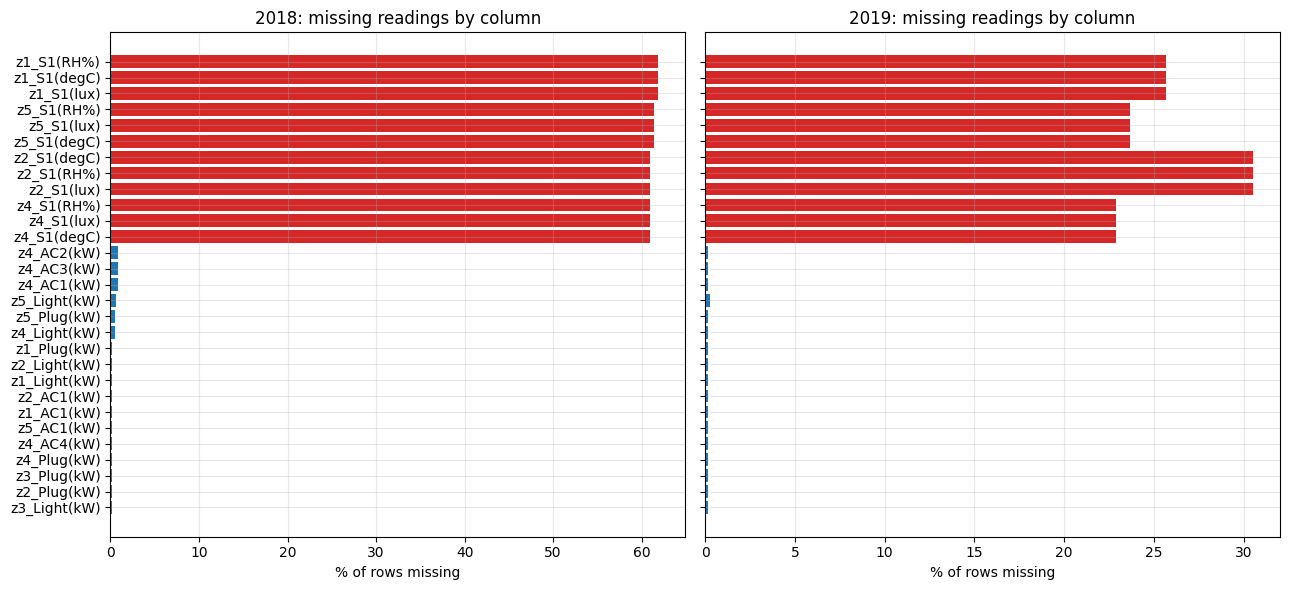

In [9]:
# Visual version of the same numbers: one bar chart per year, red = more than 5% missing.
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, (label, d) in zip(axes, [('2018', df18), ('2019', df19)]):
    pct = d[cols_to_check].isna().mean().mul(100).sort_values()
    ax.barh(pct.index, pct.values,
            color=['#d62728' if v > 5 else '#1f77b4' for v in pct.values])
    ax.set_title(f'{label}: missing readings by column')
    ax.set_xlabel('% of rows missing')
plt.tight_layout()
plt.show()

### 3.2 Sensor outage windows

Percentages tell you *how much* is missing; this tells you *when*. For every environment sensor
the code finds **contiguous runs of NaN** (`Date.diff`-free approach: a boolean mask grouped by
its own change-points) and keeps runs of ≥ 1 hour.

This is what produces the "sensors died on 13 Sep 2018 and never returned" style findings, and it
is the evidence used to justify masking in Section 10.

In [10]:
def nan_runs(ts, series, min_minutes=60):
    '''Contiguous stretches of missing values, as start / end / length.'''
    isna = series.isna()
    if not isna.any():
        return pd.DataFrame(columns=['start', 'end', 'minutes'])
    block = (isna != isna.shift()).cumsum()                      # new id per NaT↔valid change
    runs = (pd.DataFrame({'isna': isna.values, 'block': block.values, 't': ts.values})
            .loc[lambda x: x['isna']]
            .groupby('block')['t']
            .agg(['min', 'max', 'size'])
            .rename(columns={'min': 'start', 'max': 'end', 'size': 'minutes'}))
    return runs[runs['minutes'] >= min_minutes].sort_values('minutes', ascending=False)


rows = []
for label, d in [('2018', df18), ('2019', df19)]:
    for c in temp_cols:                                  # temp, RH and lux share the outages
        for _, r in nan_runs(d['Date'], d[c], min_minutes=60).iterrows():
            rows.append({'year': label, 'sensor': c,
                         'start': r['start'], 'end': r['end'],
                         'minutes': int(r['minutes'])})

outages = pd.DataFrame(rows)
print(f'{len(outages)} outage window(s) of >= 1 hour across both years')
display(outages.head(12))

# How much sensor time each year lost
display(outages.groupby('year')
        .agg(windows=('minutes', 'size'),
             lost_hours=('minutes', lambda s: round(s.sum() / 60, 1)))
        .round(1))

64 outage window(s) of >= 1 hour across both years


,year,sensor,start,end,minutes
0,2018,z1_S1(degC),2018-09-13 03:47:00,2018-12-31 23:59:00,158173
1,2018,z1_S1(degC),2018-08-17 06:47:00,2018-08-17 12:04:00,318
2,2018,z1_S1(degC),2018-08-30 05:07:00,2018-08-30 08:42:00,216
3,2018,z1_S1(degC),2018-08-01 08:42:00,2018-08-01 11:58:00,197
4,2018,z1_S1(degC),2018-09-10 08:22:00,2018-09-10 10:22:00,121
5,2018,z1_S1(degC),2018-08-05 19:02:00,2018-08-05 21:01:00,120
6,2018,z1_S1(degC),2018-08-17 01:04:00,2018-08-17 02:51:00,108
7,2018,z1_S1(degC),2018-08-30 20:32:00,2018-08-30 22:06:00,95
8,2018,z1_S1(degC),2018-08-20 06:27:00,2018-08-20 07:49:00,83
9,2018,z1_S1(degC),2018-08-30 09:25:00,2018-08-30 10:47:00,83


,windows,lost_hours
year,,
2018,30,10570.4
2019,34,6973.0


### 3.3 Zeros are *measurements*, not gaps

Share of readings equal to `0.0` kW per power column. High zero-rates are expected for
lighting (off overnight/weekends) and AC (idle at night) — they represent genuine "no load",
whereas the `NaN`s in Section 3.1 are failed reporting. Percentages differ between years mostly
because the two files cover different calendar months.

In [11]:
zero_pct = pd.DataFrame({
    'zero 2018 (%)': (df18[power_cols] == 0).mean().mul(100).round(1),
    'zero 2019 (%)': (df19[power_cols] == 0).mean().mul(100).round(1),
}).sort_values('zero 2019 (%)', ascending=False)

display(zero_pct)
print('Total NaNs still present after cleaning (both years):',
      int(df18[cols_to_check].isna().sum().sum() + df19[cols_to_check].isna().sum().sum()))

,zero 2018 (%),zero 2019 (%)
z4_AC3(kW),98.1,99.7
z4_AC1(kW),98.7,99.3
z4_AC2(kW),95.8,97.9
z5_AC1(kW),78.9,79.0
z4_AC4(kW),78.9,79.0
z1_AC1(kW),78.9,78.9
z2_AC1(kW),77.6,76.9
z5_Light(kW),55.3,56.7
z1_Light(kW),56.0,54.0
z4_Light(kW),53.8,52.9


Total NaNs still present after cleaning (both years): 3282393


## 4. Time features

The timestamp is decomposed into the calendar parts every later analysis groups by:

| Feature | Built with | Used for |
|---|---|---|
| `date` | `dt.date` | daily kWh totals, anomaly detection |
| `hour` | `dt.hour` | load profiles (hour-of-day curves) |
| `month` | `dt.month` | monthly year-on-year comparison |
| `day_of_week` / `day_name` | `dt.dayofweek` / `dt.day_name()` | weekday vs weekend |
| `is_weekend` | `day_of_week >= 5` | occupancy proxy |
| `is_occupied` | Mon–Fri **08:00–17:00** | occupied vs after-hours energy split |

`is_occupied` follows the standard office-hours assumption used in energy-audit practice
(Mon–Fri, 8 am–5 pm, i.e. hours 8…16 inclusive). Both cleaned frames are then concatenated into
one `df_all` with a `year` column so that everything from here on can be pivoted by year in a
single `groupby`.

In [12]:
def add_time_features(d):
    out = d.copy()
    dt = out['Date']
    out['date']        = dt.dt.date
    out['hour']        = dt.dt.hour
    out['month']       = dt.dt.month
    out['day_of_week'] = dt.dt.dayofweek          # Monday = 0 ... Sunday = 6
    out['day_name']    = dt.dt.day_name()
    out['is_weekend']  = out['day_of_week'] >= 5
    out['is_occupied'] = (out['day_of_week'] < 5) & out['hour'].between(8, 16)
    return out

df18 = add_time_features(df18)
df19 = add_time_features(df19)

# One frame for every year-on-year analysis from here on
df_all = pd.concat([df18, df19], ignore_index=True)

print('combined frame:', df_all.shape)
display(df_all[['Date', 'year', 'date', 'hour', 'month',
                'day_name', 'is_weekend', 'is_occupied']].head(3))

# Sanity check: rows per year and how many fall in occupied hours
display(df_all.groupby('year')
        .agg(rows=('Date', 'size'),
             days=('date', 'nunique'),
             occupied_pct=('is_occupied', lambda s: round(s.mean() * 100, 1))))

combined frame: (689128, 38)


,Date,year,date,hour,month,day_name,is_weekend,is_occupied
0,2018-07-01 00:00:00,2018,2018-07-01,0,7,Sunday,True,False
1,2018-07-01 00:01:00,2018,2018-07-01,0,7,Sunday,True,False
2,2018-07-01 00:02:00,2018,2018-07-01,0,7,Sunday,True,False


,rows,days,occupied_pct
year,,,
2018,264960,184,26.7
2019,424168,295,26.8


## 5. Energy derivation (kW → kWh)

Every power column is an **instantaneous kW reading sampled each minute**, so:

$$E_{\text{kWh}} = \sum_{\text{rows}} \frac{P_{\text{kW}}}{60\,\text{min}}$$

Derived columns (one `groupby`-free row-wise sum per set):

* `{z1…z5}_total_kW` — sum of that zone's AC + Light + Plug columns
* `floor_total_kW` — all five zones summed (whole-floor demand)
* `cooling_kW` / `lighting_kW` / `plug_kW` — end-use split across the floor
* matching `*_kWh` columns — the same values divided by 60, i.e. energy per 1-minute interval

`sum(axis=1, min_count=1)` is used so that a row where *every* relevant sensor is dead stays
`NaN` (and is later excluded) instead of silently becoming `0`. Rows with only *some* columns
missing (< 1 % of rows) sum the available readings — an under-count of well under 1 %.

In [13]:
zone_power_cols = {z: [c for c in power_cols if c.startswith(z + '_')] for z in zone_ids}

def add_energy(d):
    out = d.copy()
    # zone totals
    for z, cols in zone_power_cols.items():
        out[f'{z}_total_kW'] = out[cols].sum(axis=1, min_count=1)
    zone_tot = [f'{z}_total_kW' for z in zone_ids]
    # floor total + end-use split
    out['floor_total_kW'] = out[zone_tot].sum(axis=1, min_count=1)
    out['cooling_kW']    = out[ac_cols].sum(axis=1, min_count=1)
    out['lighting_kW']   = out[light_cols].sum(axis=1, min_count=1)
    out['plug_kW']       = out[plug_cols].sum(axis=1, min_count=1)
    # energy per minute-interval (kW * 1/60 h)
    for src in zone_tot + ['floor_total_kW', 'cooling_kW', 'lighting_kW', 'plug_kW']:
        out[src.replace('_kW', '_kWh')] = out[src] / 60
    out['floor_kWh'] = out['floor_total_kW'] / 60        # whole-floor energy per interval
    return out

df18 = add_energy(df18)
df19 = add_energy(df19)
df_all = pd.concat([df18, df19], ignore_index=True)

derived = (['floor_total_kW', 'cooling_kW', 'lighting_kW', 'plug_kW']
           + [f'{z}_total_kW' for z in zone_ids])
print(f'combined frame with derived columns: {df_all.shape}')
display(df_all[derived].describe().T)

combined frame with derived columns: (689128, 57)


,count,mean,std,min,25%,50%,75%,max
floor_total_kW,688316.0,21.664598,33.009197,0.0,0.90,4.95,20.39,166.20
cooling_kW,688292.0,12.800345,26.248675,0.0,0.00,0.00,0.00,144.50
lighting_kW,688109.0,7.203855,7.565830,0.0,0.06,3.98,16.05,61.37
plug_kW,688110.0,1.663508,1.337722,0.0,0.75,0.94,2.60,19.38
z1_total_kW,688212.0,5.961864,9.719069,0.0,0.21,0.30,4.48,51.33
z2_total_kW,688239.0,6.637727,9.622849,0.0,0.14,1.53,7.03,66.73
z3_total_kW,688109.0,1.176236,0.801891,0.0,0.32,1.22,1.91,17.61
z4_total_kW,688247.0,5.497701,10.180338,0.0,0.08,0.21,4.53,63.18
z5_total_kW,688226.0,2.393931,4.658235,0.0,0.06,0.09,2.51,47.77


## 6. Year-level comparison

Headline totals per year. **Read the `days with data` row first**: 2018 covers only Jul–Dec
(184 days) and 2019 only Jan–22 Oct (295 days), so the raw `Δ %` on total energy is *not* a
like-for-like figure.

The meaningful rows are:

* **`kWh per day`** — normalises for the different number of days observed,
* the **end-use split** (cooling / lighting / plug) — shows *what* drives consumption,
* the **per-zone kWh** — shows *where* on the floor the energy goes.

The like-for-like month-by-month comparison is Section 7.

In [14]:
def yearly_summary(d, label):
    days = d['date'].nunique()
    s = {
        'days with data': days,
        'total floor energy (kWh)': d['floor_kWh'].sum(),
        'avg demand (kW)': d['floor_total_kW'].mean(),
        'cooling (kWh)': d['cooling_kWh'].sum(),
        'lighting (kWh)': d['lighting_kWh'].sum(),
        'plug load (kWh)': d['plug_kWh'].sum(),
    }
    for z in zone_ids:
        s[f'{z} (kWh)'] = d[f'{z}_total_kWh'].sum()
    s['kWh per day'] = d['floor_kWh'].sum() / days
    return pd.Series(s, name=label)

yearly = pd.concat([yearly_summary(df18, '2018 (Jul-Dec)'),
                    yearly_summary(df19, '2019 (Jan-22 Oct)')], axis=1)
yearly['delta %'] = ((yearly.iloc[:, 1] - yearly.iloc[:, 0]) / yearly.iloc[:, 0] * 100)
display(yearly.round(1))

# End-use shares (%) — how the floor's energy splits into cooling / lighting / plug
shares = (yearly.loc[['cooling (kWh)', 'lighting (kWh)', 'plug load (kWh)']]
          / yearly.loc[['cooling (kWh)', 'lighting (kWh)', 'plug load (kWh)']].sum() * 100)
shares.index = ['cooling', 'lighting', 'plug load']
display(shares.round(1))

,2018 (Jul-Dec),2019 (Jan-22 Oct),delta %
days with data,184.0,295.0,60.3
total floor energy (kWh),92798.4,155736.4,67.8
avg demand (kW),21.0,22.1,4.8
cooling (kWh),52762.6,94077.0,78.3
lighting (kWh),32493.2,50124.1,54.3
plug load (kWh),7542.6,11535.4,52.9
z1 (kWh),25307.0,43076.8,70.2
z2 (kWh),29188.7,46950.3,60.9
z3 (kWh),5290.4,8199.3,55.0
z4 (kWh),22696.8,40366.1,77.8


,2018 (Jul-Dec),2019 (Jan-22 Oct),delta %
cooling,56.9,60.4,42.2
lighting,35.0,32.2,29.3
plug load,8.1,7.4,28.5


,2018,2019,delta %
count,264585.00,423731.00,60.15
mean,21.04,22.05,4.79
std,32.10,33.56,4.53
min,0.00,0.00,NaN
25%,0.82,0.94,14.63
50%,4.61,5.20,12.80
75%,21.32,19.97,-6.33
max,153.86,166.20,8.02


,2018 mean (kW),2019 mean (kW),delta %
z1_total_kW,5.74,6.10,6.30
z2_total_kW,6.62,6.65,0.44
z3_total_kW,1.20,1.16,-3.21
z4_total_kW,5.15,5.72,11.06
z5_total_kW,2.34,2.43,3.78


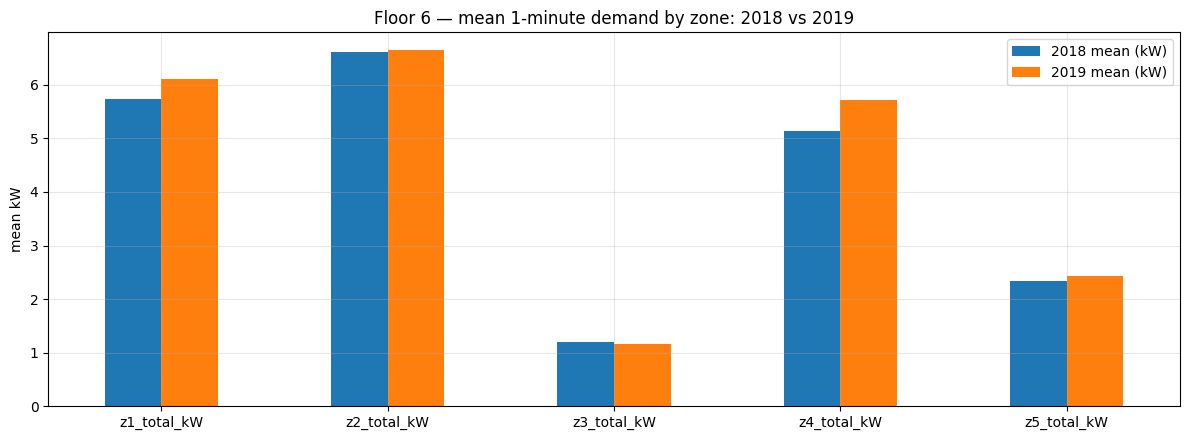

In [15]:
# Distribution of whole-floor demand (1-minute kW readings), both years side by side.
desc = pd.concat({'2018': df18['floor_total_kW'].describe(),
                  '2019': df19['floor_total_kW'].describe()}, axis=1)
desc['delta %'] = ((desc['2019'] - desc['2018']) / desc['2018'].replace(0, np.nan) * 100)
display(desc.round(2))

# Mean demand per zone per year
zone_means = pd.DataFrame({
    '2018 mean (kW)': df18[[f'{z}_total_kW' for z in zone_ids]].mean(),
    '2019 mean (kW)': df19[[f'{z}_total_kW' for z in zone_ids]].mean(),
})
zone_means['delta %'] = ((zone_means['2019 mean (kW)'] - zone_means['2018 mean (kW)'])
                         / zone_means['2018 mean (kW)'].replace(0, np.nan) * 100)
display(zone_means.round(2))

fig, ax = plt.subplots()
zone_means[['2018 mean (kW)', '2019 mean (kW)']].plot(kind='bar', ax=ax)
ax.set_ylabel('mean kW')
ax.set_title('Floor 6 — mean 1-minute demand by zone: 2018 vs 2019')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Monthly year-on-year comparison

This is the **fair** comparison. Steps:

1. `groupby(['year','month'])` sums the per-interval kWh columns into monthly energy, and counts
   the distinct `date`s in each month (`days`) so partial months can be normalised.
2. `.unstack('year')` turns the year index into columns → one row per calendar month with
   2018 and 2019 side by side.
3. `Δ %` is computed **only for months both years contain** (Jul–Oct); Nov–Dec 2019 simply does
   not exist in the file, and Jan–Jun 2018 does not exist either.
4. `kWh per day` removes the "October 2019 only has 22 days of data" effect, and each row is
   flagged as a **complete or partial month** so the raw-`Δ %` column is never read out of context
   (raw October shows ≈ −29 %, but per day it is ≈ +0.5 % — the file simply ends on 22 October).

Then the same idea is repeated **per zone on a kWh/day basis** to see *which zones* changed most.

In [16]:
zone_kwh_cols = [f'{z} kWh' for z in zone_ids]      # zone energy column names inside `monthly`

monthly = (df_all.groupby(['year', 'month'])
           .agg(days=('date', 'nunique'),
                floor_kWh=('floor_kWh', 'sum'),
                **{f'{z} kWh': (f'{z}_total_kWh', 'sum') for z in zone_ids}))
monthly['kWh per day'] = monthly['floor_kWh'] / monthly['days']

# Is each (year, month) a COMPLETE calendar month?  Needed to avoid fake year-on-year swings
# caused by partial months (October 2019 stops on the 22nd -> only 22 days of data).
import calendar
monthly['complete_month'] = [monthly['days'].loc[(y, m)] == calendar.monthrange(y, m)[1]
                             for (y, m) in monthly.index]
display(monthly.round(1))

days  floor_kWh  z1 kWh  z2 kWh  z3 kWh  z4 kWh  z5 kWh  kWh per day  complete_month
year month                                                                                      
2018 7        31    15451.7  4190.1  4650.9   867.6  4002.6  1740.4        498.4            True
     8        31    16566.3  4400.8  5458.3   945.6  4057.7  1703.8        534.4            True
     9        30    14955.1  4145.1  4664.5   902.9  3629.7  1612.8        498.5            True
     10       31    16027.3  4418.8  5044.7   892.5  3862.2  1809.1        517.0            True
     11       30    16099.0  4420.5  5068.5   870.2  3908.4  1831.3        536.6            True
     12       31    13699.2  3731.6  4301.7   811.6  3236.2  1618.1        441.9            True
2019 1        31    14965.8  4196.2  4643.5   817.0  3586.8  1722.3        482.8            True
     2        28    14355.6  4015.2  4475.1   779.0  3561.4  1524.9        512.7            True
     3        31    17047.3  4468.4  5299.0   874.8  4511.9  1893.2        549.9            True
     4        30    16288.8  3854.3  5265.4   775.6  4368.0  2025.6        543.0            True
     5        31    17597.6  4286.9  5751.2   863.4  4643.5  2052.6        567.7            True
     6        30    15900.7  4677.2  4387.5   844.0  4176.8  1815.3        530.0            True
     7        31    16668.7  4735.3  4808.4   911.0  4382.4  1831.6        537.7            True
     8        31    16069.9  4559.4  4715.4   899.4  4251.1  1644.7        518.4            True
     9        30    15415.2  4674.6  4322.3   859.9  4030.8  1527.6        513.8            True
     10       22    11426.8  3609.3  3282.6   575.2  2853.6  1106.1        519.4           False

In [17]:
# --- whole-floor view: month x year, with delta and comparability flag -------
floor_piv = monthly['floor_kWh'].unstack('year')
floor_piv.columns = [str(c) for c in floor_piv.columns]
floor_piv['delta %'] = ((floor_piv['2019'] - floor_piv['2018']) / floor_piv['2018'] * 100)

complete_piv = monthly['complete_month'].unstack('year')
both = floor_piv[['2018', '2019']].notna().all(axis=1)
full = complete_piv.all(axis=1) if complete_piv.shape[1] == 2 else pd.Series(False, index=complete_piv.index)
floor_piv['comparable'] = np.select(
    [~both, both & full],
    ['only one year present', 'both years, complete months'],
    default='both years BUT partial month -> use kWh/day')

day_piv = monthly['kWh per day'].unstack('year')
day_piv.columns = [str(c) for c in day_piv.columns]
day_piv['delta %'] = ((day_piv['2019'] - day_piv['2018']) / day_piv['2018'] * 100)

display(floor_piv.round(1))
display(day_piv.round(1))

,2018,2019,delta %,comparable
month,,,,
1,NaN,14965.8,NaN,only one year present
2,NaN,14355.6,NaN,only one year present
3,NaN,17047.3,NaN,only one year present
4,NaN,16288.8,NaN,only one year present
5,NaN,17597.6,NaN,only one year present
6,NaN,15900.7,NaN,only one year present
7,15451.7,16668.7,7.9,"both years, complete months"
8,16566.3,16069.9,-3.0,"both years, complete months"
9,14955.1,15415.2,3.1,"both years, complete months"


,2018,2019,delta %
month,,,
1,NaN,482.8,NaN
2,NaN,512.7,NaN
3,NaN,549.9,NaN
4,NaN,543.0,NaN
5,NaN,567.7,NaN
6,NaN,530.0,NaN
7,498.4,537.7,7.9
8,534.4,518.4,-3.0
9,498.5,513.8,3.1


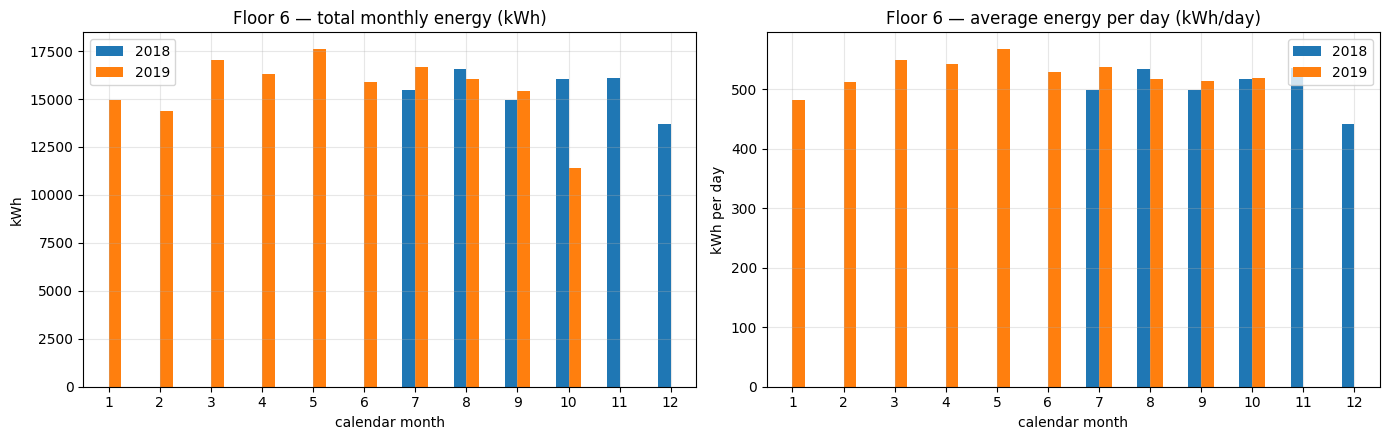

In [18]:
# --- charts: absolute monthly energy vs energy per day ----------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
floor_piv[['2018', '2019']].plot(kind='bar', ax=axes[0], color=['#1f77b4', '#ff7f0e'])
axes[0].set_title('Floor 6 — total monthly energy (kWh)')
axes[0].set_xlabel('calendar month'); axes[0].set_ylabel('kWh')
axes[0].tick_params(axis='x', rotation=0)

day_piv[['2018', '2019']].plot(kind='bar', ax=axes[1], color=['#1f77b4', '#ff7f0e'])
axes[1].set_title('Floor 6 — average energy per day (kWh/day)')
axes[1].set_xlabel('calendar month'); axes[1].set_ylabel('kWh per day')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout(); plt.show()

Months comparable across years: [7, 8, 9, 10]


,z1,z2,z3,z4,z5
month,,,,,
7,13.0,3.4,5.0,9.5,5.2
8,3.6,-13.6,-4.9,4.8,-3.5
9,12.8,-7.3,-4.8,11.1,-5.3
10,15.1,-8.3,-9.2,4.1,-13.8


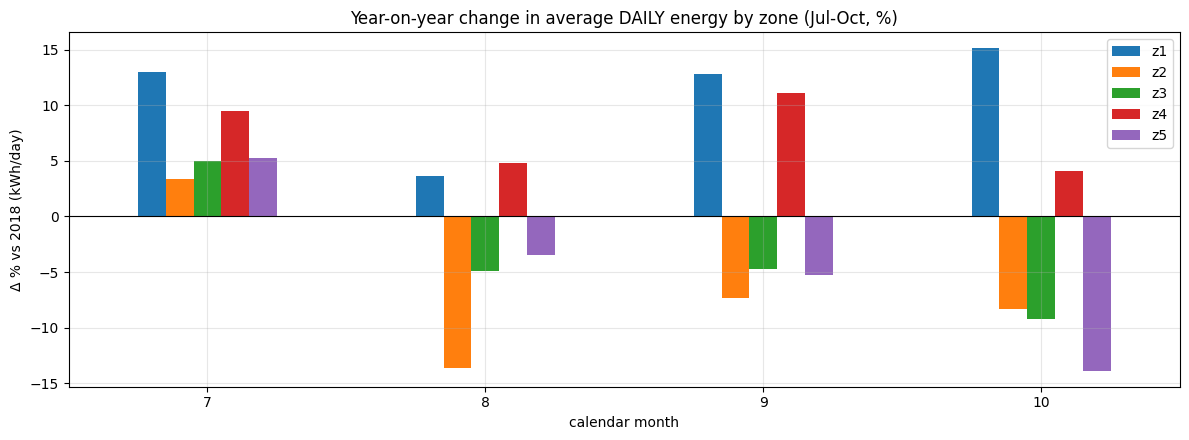

In [19]:
# --- zone-level year-on-year for the months present in BOTH years -----------
# Energy is normalised to kWh/day first, otherwise October 2019 (22 days of data)
# would look like a collapse in consumption when it is really just a shorter file.
common_months = monthly.loc[2018].index.intersection(monthly.loc[2019].index)
print('Months comparable across years:', list(common_months))

zone_2018 = monthly.loc[2018, zone_kwh_cols].div(monthly.loc[2018, 'days'], axis=0)
zone_2019 = monthly.loc[2019, zone_kwh_cols].div(monthly.loc[2019, 'days'], axis=0)

zone_yoy = ((zone_2019.loc[common_months] - zone_2018.loc[common_months])
            / zone_2018.loc[common_months] * 100)
zone_yoy.columns = zone_ids
display(zone_yoy.round(1))

ax = zone_yoy.plot(kind='bar', figsize=(12, 4.5), rot=0)
ax.axhline(0, color='black', lw=0.8)
ax.set_title('Year-on-year change in average DAILY energy by zone (Jul-Oct, %)')
ax.set_xlabel('calendar month'); ax.set_ylabel('Δ % vs 2018 (kWh/day)')
plt.tight_layout(); plt.show()

## 8. Load profiles — *when* the floor uses energy

Four complementary views, all built with `pivot_table` (reshape long data → wide table):

1. **Hour of day** — mean kW for each hour, one line per year → did the daily routine change?
2. **Hour × month heatmaps** — one heatmap per year; shows seasonal shifts in cooling and in
   working hours (colour = mean floor demand in kW).
3. **Day of week** — Mon…Sun means → weekend drop and any mid-week peak.
4. **Occupied vs after-hours** — the energy-audit split (weekday 08–17 / weekday night / weekend),
   reported both as *average kW* (how hard the building is pushed) and as *share of total kWh*
   (where the year's energy actually goes).

,2018,2019
hour,,
0,0.89,1.01
1,0.84,0.97
2,0.80,0.93
3,0.80,0.92
4,1.16,0.91
5,1.72,1.79
6,5.72,6.04
7,27.99,24.32
8,57.88,63.87


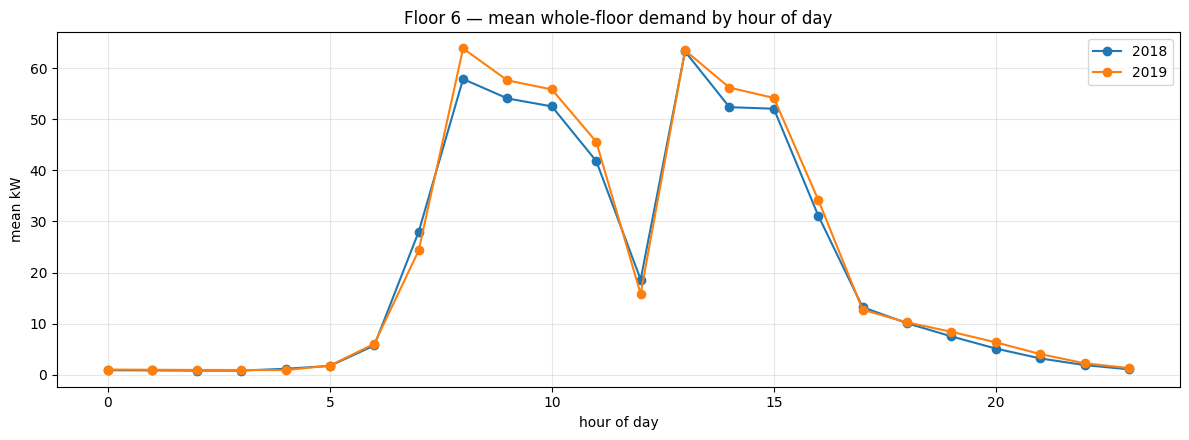

In [20]:
# 1) mean demand by hour of day, one line per year
hourly = (df_all.pivot_table(index='hour', columns='year',
                             values='floor_total_kW', aggfunc='mean'))
hourly.columns = [str(c) for c in hourly.columns]

display(hourly.round(2))
ax = hourly.plot(marker='o', figsize=(12, 4.5))
ax.set_title('Floor 6 — mean whole-floor demand by hour of day')
ax.set_xlabel('hour of day'); ax.set_ylabel('mean kW')
plt.tight_layout(); plt.show()

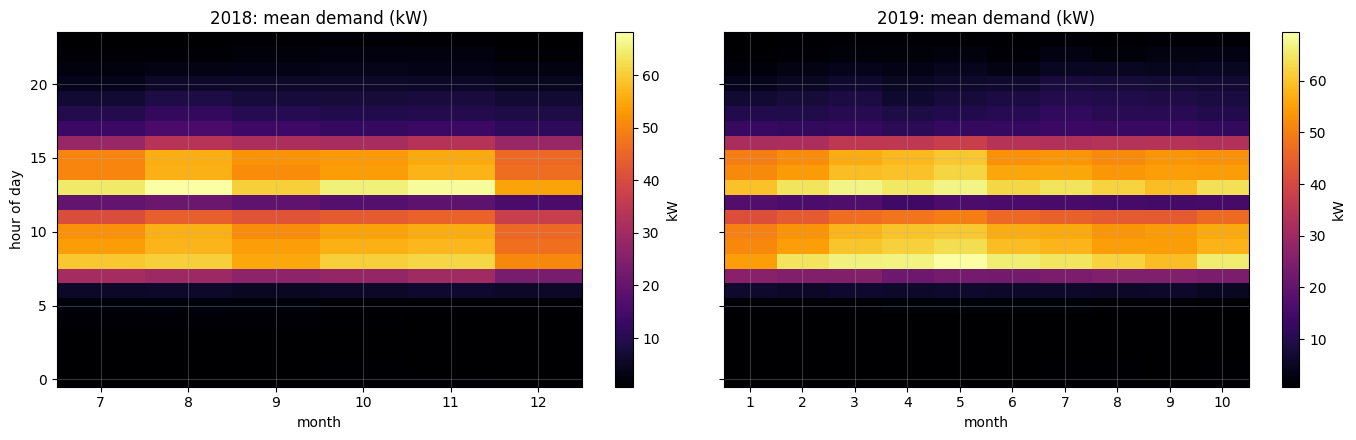

In [21]:
# 2) hour x month heatmaps (one per year) — colour = mean floor demand (kW)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (label, d) in zip(axes, [('2018', df18), ('2019', df19)]):
    piv = d.pivot_table(index='hour', columns='month',
                        values='floor_total_kW', aggfunc='mean')
    im = ax.imshow(piv.values, cmap='inferno', origin='lower', aspect='auto')
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels(piv.columns)
    ax.set_xlabel('month'); ax.set_title(f'{label}: mean demand (kW)')
    fig.colorbar(im, ax=ax, label='kW')
axes[0].set_ylabel('hour of day')
plt.tight_layout(); plt.show()

,2018,2019
day_name,,
Monday,27.29,28.21
Tuesday,29.55,29.89
Wednesday,28.34,30.51
Thursday,29.23,30.05
Friday,27.24,29.21
Saturday,2.57,3.54
Sunday,3.57,2.78


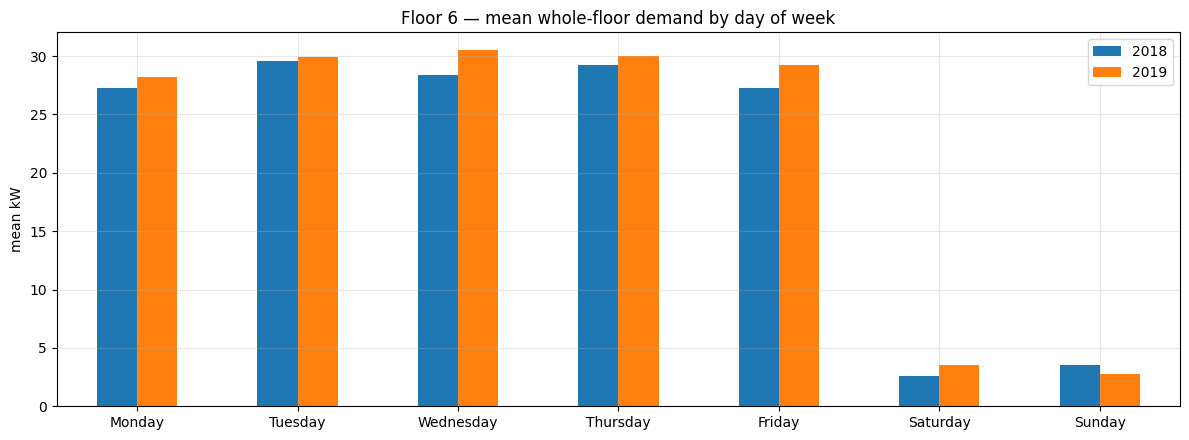

In [22]:
# 3) day-of-week profile (table first, then chart)
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow = (df_all.pivot_table(index='day_name', columns='year',
                          values='floor_total_kW', aggfunc='mean')
       .reindex(dow_order))
dow.columns = [str(c) for c in dow.columns]
display(dow.round(2))

ax = dow.plot(kind='bar', figsize=(12, 4.5))
ax.set_title('Floor 6 — mean whole-floor demand by day of week')
ax.set_xlabel(''); ax.set_ylabel('mean kW')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

,2018 mean kW,2019 mean kW
period,,
Weekday 08-17 (occupied),63.92,67.18
Weekday off-hours,7.04,7.00
Weekend,3.08,3.16


,2018 share %,2019 share %
period,,
Weekday 08-17 (occupied),80.9,81.7
Weekday off-hours,14.9,14.2
Weekend,4.2,4.1


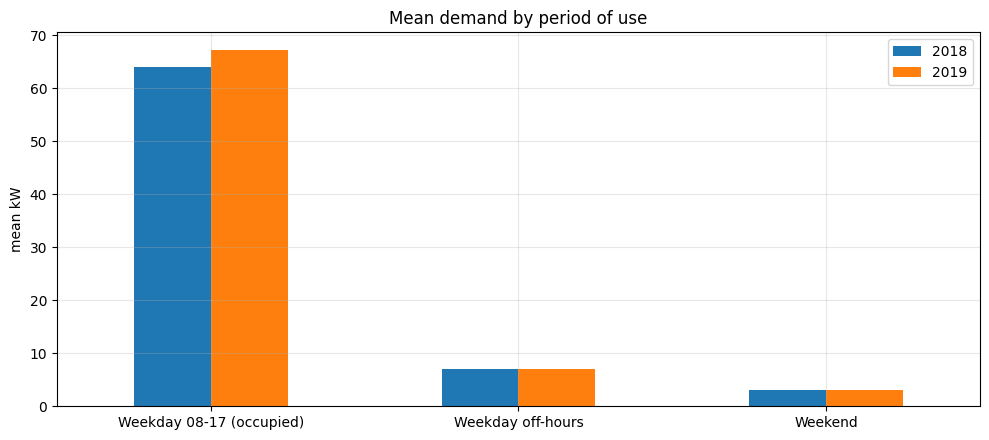

In [23]:
# 4) occupied / night / weekend split — as demand (kW) AND as share of energy (%)
df_all['period'] = np.select(
    [df_all['is_occupied'], df_all['is_weekend']],
    ['Weekday 08-17 (occupied)', 'Weekend'],
    default='Weekday off-hours')
period_order = ['Weekday 08-17 (occupied)', 'Weekday off-hours', 'Weekend']

period_kW = (df_all.pivot_table(index='period', columns='year',
                                values='floor_total_kW', aggfunc='mean')
             .reindex(period_order))
period_kWh = (df_all.pivot_table(index='period', columns='year',
                                 values='floor_kWh', aggfunc='sum')
              .reindex(period_order))
period_share = period_kWh / period_kWh.sum() * 100

for c in [period_kW, period_kWh, period_share]:
    c.columns = [str(x) for x in c.columns]

display(period_kW.round(2).rename(columns={'2018': '2018 mean kW', '2019': '2019 mean kW'}))
display(period_share.round(1).rename(columns={'2018': '2018 share %', '2019': '2019 share %'}))

ax = period_kW.plot(kind='bar', figsize=(10, 4.5))
ax.set_title('Mean demand by period of use')
ax.set_ylabel('mean kW'); ax.set_xlabel('')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

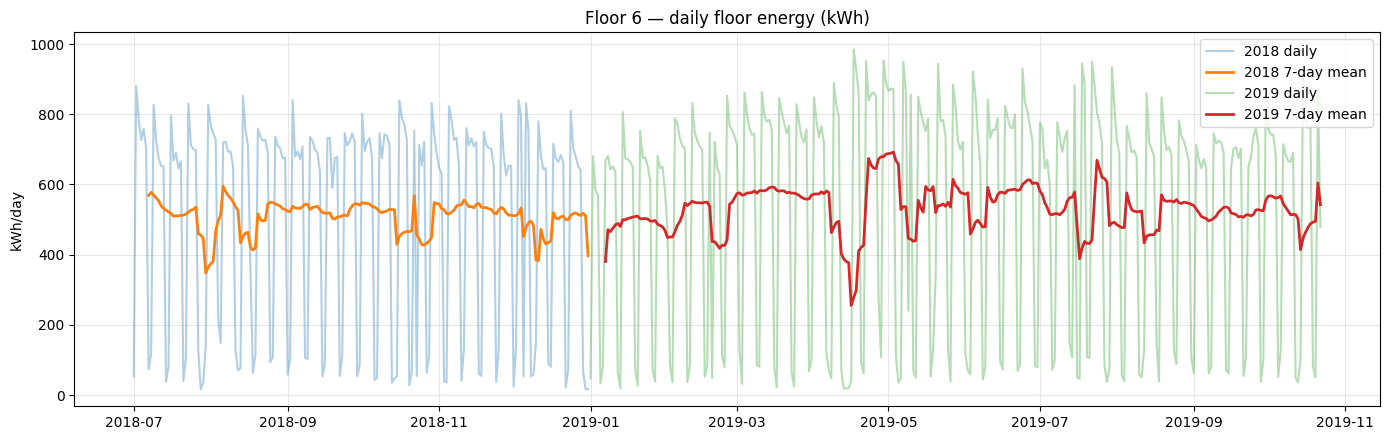

,2018,2019
count,184.0,295.0
mean,504.3,527.9
std,308.5,329.6
min,16.4,18.8
25%,106.3,97.3
50%,678.2,692.7
75%,727.6,770.3
max,880.3,985.0


In [24]:
# Daily energy trend — shows both the year boundary and any week-to-week drift.
daily_kwh = {}
for label, d in [('2018', df18), ('2019', df19)]:
    s = d.groupby('date')['floor_kWh'].sum()
    s.index = pd.to_datetime(s.index)
    daily_kwh[label] = s

fig, ax = plt.subplots(figsize=(14, 4.5))
for label, s in daily_kwh.items():
    ax.plot(s.index, s.values, alpha=0.35, label=f'{label} daily')
    ax.plot(s.index, s.rolling(7, min_periods=7).mean().values,
            lw=2, label=f'{label} 7-day mean')
ax.set_title('Floor 6 — daily floor energy (kWh)')
ax.set_ylabel('kWh/day'); ax.legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame({k: v.describe() for k, v in daily_kwh.items()}).round(1))

## 9. Peak, base load and load factor

Standard energy-audit demand metrics, computed for every zone **and** for the whole floor, per
year:

| Metric | Definition | Why it matters |
|---|---|---|
| **Peak 1-min** | maximum 1-minute kW | worst-case instantaneous demand |
| **Peak 15-min avg** | max of the 15-minute rolling mean | the number a utility actually bills on (settled demand is averaged) |
| **Average demand** | mean kW | drives total energy |
| **Base load (p5)** | 5th percentile of kW | the always-on load when the floor is idle |
| **Load factor** | average ÷ peak | efficiency of demand: **close to 1 = flat, expensive-but-steady; low = spiky**, meaning capacity is installed but barely used |

`Series.rolling(15).mean()` produces the utility-style 15-minute window.

In [25]:
def demand_metrics(s):
    return pd.Series({
        'Peak 1-min (kW)': s.max(),
        'Peak 15-min avg (kW)': s.rolling(15, min_periods=15).mean().max(),
        'Average demand (kW)': s.mean(),
        'Base load p5 (kW)': s.quantile(0.05),
        'Load factor': s.mean() / s.max(),
        'Std dev (kW)': s.std(),
    })

metric_cols = [f'{z}_total_kW' for z in zone_ids] + ['floor_total_kW']
tbl18 = pd.concat({c: demand_metrics(df18[c]) for c in metric_cols}, axis=1)
tbl19 = pd.concat({c: demand_metrics(df19[c]) for c in metric_cols}, axis=1)
tbl18.columns = [c.replace('_total_kW', '') for c in tbl18.columns]
tbl19.columns = [c.replace('_total_kW', '') for c in tbl19.columns]

print('=== 2018 (Jul-Dec) ==='); display(tbl18.round(2))
print('=== 2019 (Jan-22 Oct) ==='); display(tbl19.round(2))

delta_pct = ((tbl19 - tbl18) / tbl18.replace(0, np.nan) * 100)
print('=== delta % ==='); display(delta_pct.round(1))

=== 2018 (Jul-Dec) ===


,z1,z2,z3,z4,z5,floor
Peak 1-min (kW),50.99,66.73,17.61,55.48,46.68,153.86
Peak 15-min avg (kW),33.36,34.98,2.98,41.92,23.48,133.10
Average demand (kW),5.74,6.62,1.20,5.15,2.34,21.04
Base load p5 (kW),0.12,0.02,0.28,0.04,0.01,0.62
Load factor,0.11,0.10,0.07,0.09,0.05,0.14
Std dev (kW),9.31,9.58,0.83,10.23,4.53,32.10


=== 2019 (Jan-22 Oct) ===


,z1,z2,z3,z4,z5,floor
Peak 1-min (kW),51.33,59.87,3.62,63.18,47.77,166.20
Peak 15-min avg (kW),41.29,34.75,3.01,43.49,23.47,135.56
Average demand (kW),6.10,6.65,1.16,5.72,2.43,22.05
Base load p5 (kW),0.14,0.06,0.27,0.04,0.03,0.69
Load factor,0.12,0.11,0.32,0.09,0.05,0.13
Std dev (kW),9.96,9.65,0.78,10.14,4.73,33.56


=== delta % ===


,z1,z2,z3,z4,z5,floor
Peak 1-min (kW),0.7,-10.3,-79.4,13.9,2.3,8.0
Peak 15-min avg (kW),23.8,-0.7,1.0,3.8,-0.0,1.9
Average demand (kW),6.3,0.4,-3.2,11.1,3.8,4.8
Base load p5 (kW),16.7,200.0,-3.6,0.0,200.0,11.3
Load factor,5.6,12.0,370.8,-2.5,1.4,-3.0
Std dev (kW),7.0,0.7,-5.6,-0.9,4.4,4.5


## 10. Indoor environment (temperature, humidity, illuminance)

**This section is deliberately defensive.** From Section 3 we know the environment sensors are
missing ~61 % of rows in 2018 and ~23–31 % in 2019. So:

1. **Measure coverage first** — `%` of rows with a valid reading per year × month × sensor.
   Coverage is shown as a table and a heatmap (green = live, red = dead).
2. **Mask unreliable cells** — any year/month with **less than 50 % coverage** is set to `NaN`
   before plotting, so a month where the sensor was off for three weeks does not silently
   become an average of whatever happened to be reported.
3. Only then are **monthly means** and **year summaries** computed.

Consequence: 2018 temperature lines stop after the sensors failed (mid-Sep), and Jan–Mar 2019 is
blank — that is the honest result, not a plotting bug.

z1    z2    z4    z5
year month                        
2018 7      96.0  96.0  95.0  97.0
     8      93.0  96.0  94.0  96.0
     9      39.0  41.0  45.0  37.0
     10      0.0   0.0   0.0   0.0
     11      0.0   0.0   0.0   0.0
     12      0.0   0.0   0.0   0.0
2019 1       0.0   0.0   0.0   0.0
     2       0.0   0.0   0.0   0.0
     3      81.0  81.0  81.0  81.0
     4      99.0  98.0  99.0  95.0
     5      91.0  98.0  99.0  99.0
     6      80.0  99.0  99.0  99.0
     7      98.0  97.0  98.0  98.0
     8      99.0  98.0  99.0  98.0
     9      99.0  98.0  98.0  97.0
     10     99.0   2.0  99.0  98.0

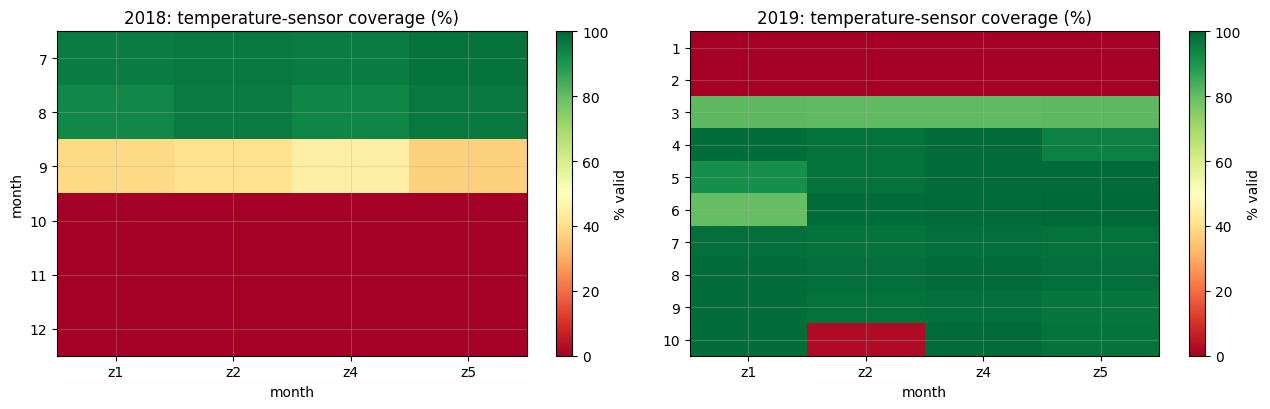

In [26]:
# Coverage = % of rows in each year/month that carry a valid temperature reading.
# (built from a boolean mask so no groupby.apply is needed)
notna_mask = df_all[temp_cols].notna().astype(int)
coverage = notna_mask.groupby([df_all['year'], df_all['month']]).mean().mul(100)
coverage.columns = [c.split('_')[0] for c in coverage.columns]     # z1, z2, z4, z5
display(coverage.round(0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, yr in zip(axes, [2018, 2019]):
    sub = coverage.loc[yr]
    im = ax.imshow(sub.values, cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(len(sub.columns)))
    ax.set_xticklabels(sub.columns)
    ax.set_yticks(range(len(sub.index)))
    ax.set_yticklabels(sub.index)
    ax.set_xlabel('month')
    ax.set_title(f'{yr}: temperature-sensor coverage (%)')
    fig.colorbar(im, ax=ax, label='% valid')
axes[0].set_ylabel('month')
plt.tight_layout(); plt.show()

In [27]:
MIN_COVERAGE = 50          # % of rows that must be valid before a month is reported

def monthly_env_means(cols):
    '''Monthly means per zone, masked where sensor coverage < MIN_COVERAGE.'''
    means = df_all.groupby(['year', 'month'])[cols].mean()
    cov = (df_all[cols].notna().astype(int)
           .groupby([df_all['year'], df_all['month']]).mean().mul(100))
    means = means.where(cov >= MIN_COVERAGE)
    means.columns = [c.split('_')[0] for c in means.columns]
    return means

temp_m = monthly_env_means(temp_cols)
rh_m   = monthly_env_means(rh_cols)
lux_m  = monthly_env_means(lux_cols)

display(temp_m.round(2))
display(rh_m.round(1))

z1     z2     z4     z5
year month                            
2018 7      27.21  26.51  26.35  27.45
     8      27.24  26.30  26.28  27.14
     9        NaN    NaN    NaN    NaN
     10       NaN    NaN    NaN    NaN
     11       NaN    NaN    NaN    NaN
     12       NaN    NaN    NaN    NaN
2019 1        NaN    NaN    NaN    NaN
     2        NaN    NaN    NaN    NaN
     3      25.45  25.27  24.65  25.05
     4      26.93  26.17  26.06  25.96
     5      26.24  25.18  25.62  25.51
     6      25.13  25.28  25.46  25.43
     7      25.15  24.88  25.31  25.32
     8      24.57  24.60  24.73  24.87
     9      23.86  23.95  24.29  24.56
     10     24.71    NaN  24.66  24.96

z1    z2    z4    z5
year month                        
2018 7      63.6  65.2  67.1  65.1
     8      58.9  62.1  62.8  64.4
     9       NaN   NaN   NaN   NaN
     10      NaN   NaN   NaN   NaN
     11      NaN   NaN   NaN   NaN
     12      NaN   NaN   NaN   NaN
2019 1       NaN   NaN   NaN   NaN
     2       NaN   NaN   NaN   NaN
     3      63.4  62.0  65.6  64.8
     4      64.4  64.0  65.0  67.2
     5      60.1  60.5  60.1  63.5
     6      65.1  63.6  61.3  64.1
     7      65.3  63.6  60.9  63.5
     8      65.7  62.9  60.7  62.8
     9      67.9  64.3  61.2  62.0
     10     67.5   NaN  61.3  61.7

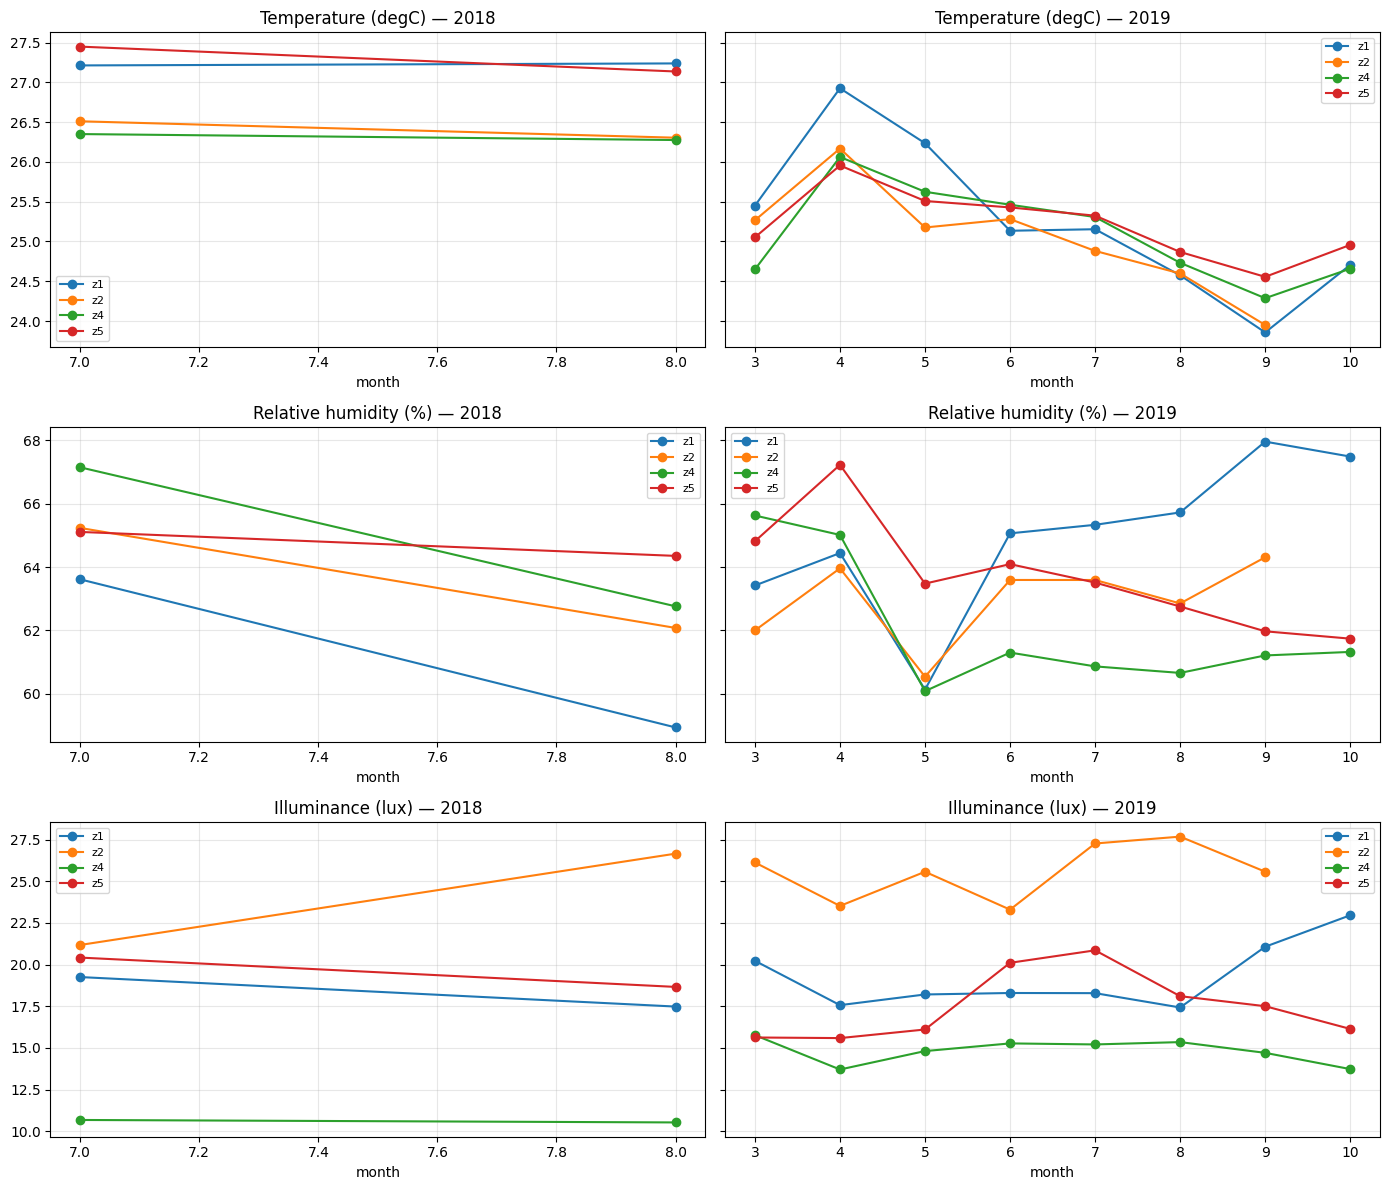

In [28]:
# Monthly means by year, one panel per metric. Gaps = masked low-coverage months.
metrics = [('Temperature (degC)', temp_m, 2),
           ('Relative humidity (%)', rh_m, 1),
           ('Illuminance (lux)', lux_m, 0)]

fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharey='row')
for row, (title, tbl, dec) in enumerate(metrics):
    for col, yr in enumerate([2018, 2019]):
        ax = axes[row, col]
        if yr in tbl.index.get_level_values(0):
            tbl.loc[yr].plot(ax=ax, marker='o')
        ax.set_title(f'{title} — {yr}')
        ax.set_xlabel('month')
        ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [29]:
# Year-level environment summary, computed ONLY over valid readings.
def env_summary(d, label):
    temp = d[temp_cols].to_numpy().ravel(); temp = temp[~np.isnan(temp)]
    rh = d[rh_cols].to_numpy().ravel();     rh = rh[~np.isnan(rh)]
    lux = d[lux_cols].to_numpy().ravel();   lux = lux[~np.isnan(lux)]
    return pd.Series({
        'valid sensor readings': int(temp.size),
        'temp mean (degC)': np.nanmean(temp),
        'temp min (degC)': np.nanmin(temp),
        'temp max (degC)': np.nanmax(temp),
        'temp std (degC)': np.nanstd(temp),
        'RH mean (%)': np.nanmean(rh),
        'lux mean': np.nanmean(lux),
        'lux max': np.nanmax(lux),
    }, name=label)

display(pd.concat([env_summary(df18, '2018'), env_summary(df19, '2019')], axis=1).round(2))

,2018,2019
valid sensor readings,410486.00,1261084.00
temp mean (degC),26.78,25.16
temp min (degC),19.51,17.90
temp max (degC),32.70,32.90
temp std (degC),1.88,2.25
RH mean (%),63.47,63.39
lux mean,18.01,19.13
lux max,73.00,85.00


## 11. Correlations

`DataFrame.corr()` (Pearson) answers two questions:

* **Does the cooling load react to indoor temperature?** — correlation between `cooling_kW` and
  each zone's `degC` should be positive if AC works as expected (hotter room → more AC).
* **Did the relationships change between years?** — the same matrix is computed separately for
  2018 and 2019 and drawn side by side.

Caveat kept in mind: correlations are computed only over rows where *both* values exist, so for
2018 they are effectively based on the Jul–mid-Sep window when the sensors were alive, and the
sample size shrinks accordingly.

**How to read the sign:** `cooling` vs indoor temperature comes out **negative** (≈ −0.6 to −0.8)
in both years. That is expected for *indoor* sensors: the temperature probe sits in the zone the
AC is actively cooling, so at the moments the AC draws the most power the room is being pulled
*down* in temperature. It is a control-loop artefact, not evidence of malfunction — and it is
almost identical in 2018 and 2019, i.e. the AC/sensor relationship did not change.

Complete cases used for temp-vs-power: 2018 = 88,687 rows | 2019 = 272,182 rows


C:\Users\Willi\AppData\Local\Temp\ipykernel_36012\3114577240.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


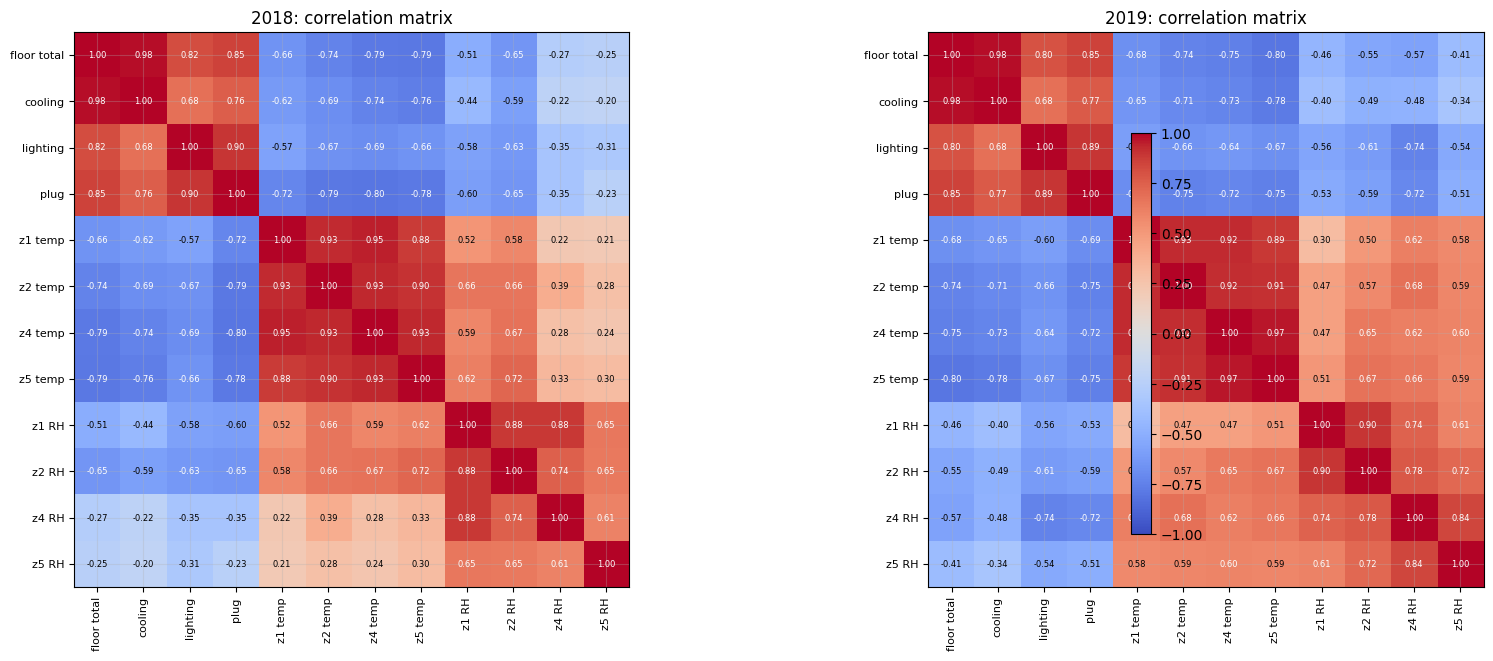

In [30]:
corr_cols = ['floor_total_kW', 'cooling_kW', 'lighting_kW', 'plug_kW'] + temp_cols + rh_cols

def short_label(c):
    if c.endswith('_S1(degC)'):
        return c.split('_')[0] + ' temp'
    if c.endswith('_S1(RH%)'):
        return c.split('_')[0] + ' RH'
    # power columns: 'floor_total_kW' -> 'floor total', 'cooling_kW' -> 'cooling'
    return c.replace('_total_kW', ' total').replace('_kW', '')

short = {c: short_label(c) for c in corr_cols}

def corr_of(d):
    return d[corr_cols].corr().rename(index=short, columns=short)

corr18, corr19 = corr_of(df18), corr_of(df19)

# Sample sizes actually used (rows where both values are present)
n18 = df18[temp_cols + ['floor_total_kW']].dropna().shape[0]
n19 = df19[temp_cols + ['floor_total_kW']].dropna().shape[0]
print(f'Complete cases used for temp-vs-power: 2018 = {n18:,} rows | 2019 = {n19:,} rows')

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, m, title in zip(axes, [corr18, corr19], ['2018', '2019']):
    im = ax.imshow(m.values, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(m)))
    ax.set_xticklabels(m.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(m)))
    ax.set_yticklabels(m.index, fontsize=8)
    for i in range(len(m)):
        for j in range(len(m)):
            v = m.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=6,
                        color='white' if abs(v) > 0.6 else 'black')
    ax.set_title(f'{title}: correlation matrix')
fig.colorbar(im, ax=axes, shrink=0.8)
plt.tight_layout(); plt.show()

In [31]:
# Just the floor's total demand against everything else — easiest to read
key = pd.DataFrame({'2018': corr18.loc['floor total'], '2019': corr19.loc['floor total']})
key = key.drop(index='floor total').sort_values('2019', key=lambda s: s.abs(), ascending=False)
display(key.round(2))

# The AC-vs-temperature relationship, zone by zone
ac_temp = pd.DataFrame({
    '2018 corr(cooling, zone temp)': [corr18.loc['cooling', short[c]] for c in temp_cols],
    '2019 corr(cooling, zone temp)': [corr19.loc['cooling', short[c]] for c in temp_cols],
}, index=[c.split('_')[0] for c in temp_cols])
display(ac_temp.round(2))

,2018,2019
cooling,0.98,0.98
plug,0.85,0.85
lighting,0.82,0.80
z5 temp,-0.79,-0.80
z4 temp,-0.79,-0.75
z2 temp,-0.74,-0.74
z1 temp,-0.66,-0.68
z4 RH,-0.27,-0.57
z2 RH,-0.65,-0.55
z1 RH,-0.51,-0.46


,"2018 corr(cooling, zone temp)","2019 corr(cooling, zone temp)"
z1,-0.62,-0.65
z2,-0.69,-0.71
z4,-0.74,-0.73
z5,-0.76,-0.78


## 12. Anomaly detection on daily energy

Two statistical tests are used, because a single test misleads on this dataset:

1. **Tukey IQR fences, computed separately for weekdays and weekends.**
   Daily energy on Floor 6 is strongly *bimodal* (weekday ≈ 680 kWh vs weekend ≈ 100 kWh), so
   one set of fences per year pushes the upper fence above every observed day and flags nothing.
   Splitting the population by day type makes the fences useful:
   `low fence = Q1 − 1.5·IQR`, `high fence = Q3 + 1.5·IQR`.
   Low flags → holiday / shutdown / data loss. High flags → extreme weather, special event, fault.
2. **Day-of-week z-score** — each day is compared with the *same weekday of the same year*:
   `z = (kWh − μ_dow) / σ_dow`. Anything with `|z| ≥ 2.5` is unusual *for that specific day*,
   which catches e.g. a Friday that behaved like a Sunday even when the IQR fences do not fire.

Also reported: the ten highest-energy days (with day-of-week and z-score) and the five highest
1-minute demand spikes — the moments that set the floor's peak-load requirement.

In [32]:
# --- daily energy table + anomaly flags -------------------------------------
daily = (df_all.groupby(['year', 'date'])
         .agg(kWh=('floor_kWh', 'sum'),
              avg_kW=('floor_total_kW', 'mean'),
              reported_minutes=('floor_total_kW', 'count'))
         .reset_index())
daily['day_of_week'] = pd.to_datetime(daily['date']).dt.dayofweek
daily['day_name'] = pd.to_datetime(daily['date']).dt.day_name()
daily['is_weekend'] = daily['day_of_week'] >= 5

# (1) Tukey fences per YEAR and DAY TYPE (weekday vs weekend are different populations)
stats = daily.groupby(['year', 'is_weekend'])['kWh'].describe(percentiles=[0.25, 0.75])
fences = stats[['25%', '75%']].rename(columns={'25%': 'q1', '75%': 'q3'})
daily = daily.merge(fences, on=['year', 'is_weekend'], how='left')
iqr = daily['q3'] - daily['q1']
daily['low_fence'] = daily['q1'] - 1.5 * iqr
daily['high_fence'] = daily['q3'] + 1.5 * iqr
daily['flag'] = np.select([daily['kWh'] > daily['high_fence'],
                           daily['kWh'] < daily['low_fence']],
                          ['HIGH', 'low'], default='')

# (2) z-score against the same weekday of the same year
dow_stats = (daily.groupby(['year', 'day_of_week'])['kWh']
             .agg(['mean', 'std'])
             .rename(columns={'mean': 'dow_mean', 'std': 'dow_std'}))
daily = daily.merge(dow_stats, on=['year', 'day_of_week'], how='left')
daily['z'] = (daily['kWh'] - daily['dow_mean']) / daily['dow_std']
daily['flag_z'] = np.select([daily['z'] >= 2.5, daily['z'] <= -2.5],
                            ['HIGH', 'LOW'], default='')

display(stats.round(1))
print('--- Tukey IQR flags ---')
display(pd.crosstab(daily['flag'], daily['year'], margins=True))
print('--- day-of-week z-score flags (|z| >= 2.5) ---')
display(pd.crosstab(daily['flag_z'], daily['year'], margins=True))

count   mean    std   min    25%    50%    75%    max
year is_weekend                                                       
2018 False       131.0  678.5  165.0  16.6  673.7  711.3  744.5  880.3
     True         53.0   74.0   40.1  16.4   42.5   63.9  102.9  221.8
2019 False       211.0  708.0  192.6  19.5  679.9  738.1  800.8  985.0
     True         84.0   75.7   39.0  18.8   50.0   71.8   96.2  281.1

--- Tukey IQR flags ---


year,2018,2019,All
flag,,,
,172,276,448
HIGH,3,2,5
low,9,17,26
All,184,295,479


--- day-of-week z-score flags (|z| >= 2.5) ---


year,2018,2019,All
flag_z,,,
,179,287,466
HIGH,2,1,3
LOW,3,7,10
All,184,295,479


In [33]:
# The ten most energy-intensive days on Floor 6
top10 = (daily.nlargest(10, 'kWh')
         [['year', 'date', 'day_name', 'kWh', 'avg_kW', 'high_fence', 'flag', 'z']])
display(top10.round(1))

# The ten days that are most unusual *for their own day of week* (largest |z|)
unusual = (daily.reindex(daily['z'].abs().sort_values(ascending=False).index).head(10)
           [['year', 'date', 'day_name', 'kWh', 'dow_mean', 'z', 'flag_z']])
display(unusual.round(1))

# The five highest instantaneous demand spikes (1-minute readings)
peak_rows = (df_all.nlargest(5, 'floor_total_kW')
             [['Date', 'floor_total_kW', 'cooling_kW', 'lighting_kW', 'plug_kW']]
             .reset_index(drop=True))
display(peak_rows.round(2))

,year,date,day_name,kWh,avg_kW,high_fence,flag,z
290,2019,2019-04-17,Wednesday,985.0,41.0,982.1,HIGH,1.9
302,2019,2019-04-29,Monday,953.9,39.7,982.1,,0.9
295,2019,2019-04-22,Monday,951.9,39.7,982.1,,0.9
386,2019,2019-07-22,Monday,949.9,39.6,982.1,,0.9
310,2019,2019-05-07,Tuesday,949.4,39.6,982.1,,1.0
382,2019,2019-07-18,Thursday,944.9,39.4,982.1,,2.1
324,2019,2019-05-21,Tuesday,943.9,39.3,982.1,,1.0
394,2019,2019-07-30,Tuesday,934.1,38.9,982.1,,1.0
358,2019,2019-06-24,Monday,929.8,38.7,982.1,,0.9
291,2019,2019-04-18,Thursday,928.9,38.7,982.1,,1.9


,year,date,day_name,kWh,dow_mean,z,flag_z
381,2019,2019-07-17,Wednesday,45.7,732.3,-5.3,LOW
285,2019,2019-04-12,Friday,70.6,699.7,-4.8,LOW
157,2018,2018-12-05,Wednesday,52.9,679.5,-4.7,LOW
114,2018,2018-10-23,Tuesday,54.1,709.3,-4.6,LOW
312,2019,2019-05-09,Thursday,240.0,721.2,-4.5,LOW
300,2019,2019-04-27,Saturday,281.1,84.6,4.4,HIGH
26,2018,2018-07-27,Friday,129.5,648.3,-4.1,LOW
34,2018,2018-08-04,Saturday,221.8,61.7,3.8,HIGH
289,2019,2019-04-16,Tuesday,40.4,710.1,-2.9,LOW
184,2019,2019-01-01,Tuesday,47.1,710.1,-2.8,LOW


,Date,floor_total_kW,cooling_kW,lighting_kW,plug_kW
0,2019-02-12 15:14:00,166.20,144.50,19.03,2.67
1,2018-07-02 13:27:00,153.86,107.10,37.27,9.49
2,2018-07-23 13:08:00,149.96,107.01,33.96,8.99
3,2019-10-17 13:14:00,147.73,127.87,16.11,3.75
4,2019-10-17 08:01:00,147.56,130.70,14.62,2.24


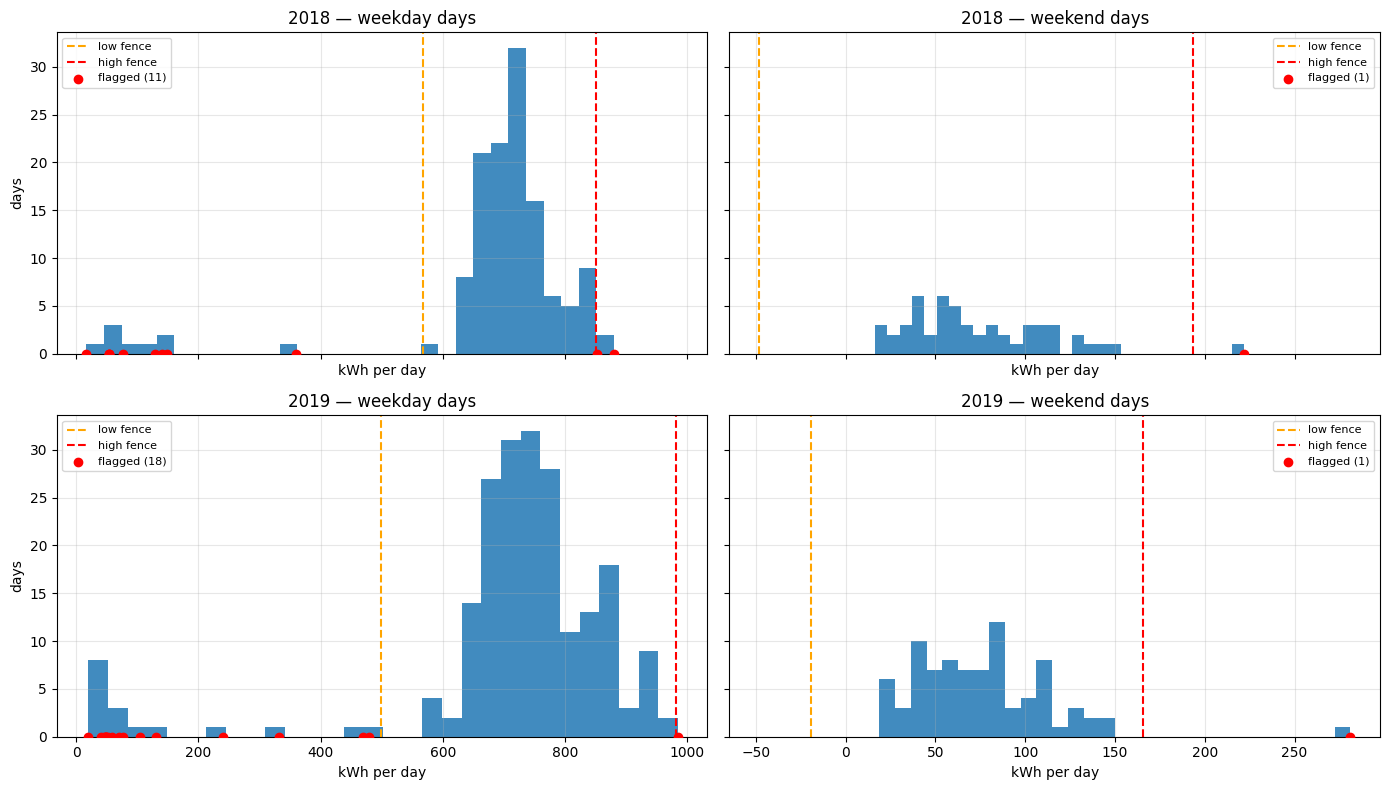

In [34]:
# Distribution of daily kWh: rows = year, columns = weekday / weekend.
# Dashed lines = Tukey fences for that population, red dots = flagged days.
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex='col', sharey='row')
for r, yr in enumerate([2018, 2019]):
    for c, wknd in enumerate([False, True]):
        ax = axes[r, c]
        g = daily[(daily['year'] == yr) & (daily['is_weekend'] == wknd)]
        ax.hist(g['kWh'], bins=30, color='#1f77b4', alpha=0.85)
        ax.axvline(g['low_fence'].iloc[0], color='orange', ls='--', label='low fence')
        ax.axvline(g['high_fence'].iloc[0], color='red', ls='--', label='high fence')
        flagged = g[g['flag'] != '']
        ax.scatter(flagged['kWh'], np.zeros(len(flagged)), color='red', zorder=3,
                   label=f'flagged ({len(flagged)})')
        ax.set_title(f"{yr} — {'weekend' if wknd else 'weekday'} days")
        ax.set_xlabel('kWh per day')
        ax.legend(fontsize=8)
axes[0, 0].set_ylabel('days')
axes[1, 0].set_ylabel('days')
plt.tight_layout(); plt.show()

## 13. Findings

Numbers below are produced by the cells above (2018 = 1 Jul – 31 Dec, 2019 = 1 Jan – 22 Oct).

### Data quality (Section 3)

* Both files are **complete 1-minute series**: 264,960 rows (2018) and 424,168 valid rows (2019),
  zero missing minutes, zero duplicate timestamps — after dropping **1 corrupt row** from the 2019
  file (the junk `Date = "2"` line at the end).
* Power columns are **0.36 % (2018) / 0.16 % (2019) missing** → energy figures are reliable.
* Environment sensors are **61.3 % missing in 2018 and 25.7 % in 2019**. The outage table shows
  *why*: all four 2018 sensors die **between 12 and 15 September 2018 and never come back**
  (30 windows, 10,570 sensor-hours lost), while 2019 loses 1 Jan – 6 Mar and 1 – 22 Oct
  (34 windows, 6,973 hours). Any 2018 vs 2019 indoor-climate claim must therefore be
  restricted to **Jul – mid-Sep 2018 vs Mar – Oct 2019**, which is exactly what Section 10 does.
* Zeros are real measurements, not gaps: Zone 4's AC1–AC3 are at `0.0` kW **96–99.7 %** of the
  time (barely used), while plug loads are essentially never off.

### Energy: did Floor 6 use more in 2019? (Sections 6–7)

* Raw totals: **92,798 kWh (184 days)** vs **155,736 kWh (295 days)** — meaningless as a Δ of
  +67.8 % because the two files cover different periods.
* Normalised: **504 → 528 kWh per day (+4.7 %)**, average demand **21.04 → 22.05 kW (+4.8 %)**.
* End-use mix shifted towards cooling: **cooling 56.9 % → 60.4 %**, lighting 35.0 % → 32.2 %,
  plug load 8.1 % → 7.4 % of floor energy.
* Fair month-on-year (kWh/day, Jul–Oct): **Jul +7.9 %, Aug −3.0 %, Sep +3.1 %, Oct +0.5 %** —
  i.e. essentially flat, with July the only month of real growth. (The *raw* October Δ of
  −28.7 % is an artefact: the 2019 file stops on 22 October — flagged as a partial month.)
* By zone on the same per-day basis, October 2019 vs October 2018: **Zone 1 +15.1 %**,
  Zone 4 +4.1 %, but **Zone 2 −8.3 %, Zone 3 −9.2 %, Zone 5 −13.8 %** — the floor got more
  uneven between years; mean demand moved most in **Zone 4 (+11.1 %)**.

### When is the energy used? (Section 8)

* The daily routine barely changed: occupied-hours demand **63.9 → 67.2 kW (+5.1 %)**,
  after-hours **7.04 → 7.00 kW**, weekend **3.08 → 3.16 kW**.
* Occupied hours (Mon–Fri 08–17) account for **80.9 % (2018) → 81.7 % (2019)** of all energy;
  nights 14.9 % → 14.2 %; weekends only ~4 %. This is a classic office load shape.
* Hourly profile: two peaks — **08:00 (57.9 → 63.9 kW)** and **13:00 (63.3 → 63.5 kW)** — with a
  midday dip at 12:00 and a night trough at 02–03:00 (< 1 kW).
* Weekdays 27–30.5 kW vs weekends 2.6–3.6 kW — about a **ten-fold drop** at weekends; Sundays
  and Saturdays are the two lightest days.

### Peak / load (Section 9)

* Floor peak 1-minute: **153.9 → 166.2 kW (+8.0 %)**; utility-style 15-minute peak
  **133.1 → 135.6 kW (+1.9 %)** — the sustained peak barely moved even though the instantaneous
  spike rose.
* **Load factor ≈ 0.13–0.14** for the floor (0.05–0.12 by zone, except Zone 3 at 0.32 in 2019 —
  it has no AC, so its demand is far flatter): demand is very spiky relative to average
  load — capacity is installed for a peak that occurs for only a few minutes (the top spike is
  **2019-02-12 15:14, 166.2 kW of which 144.5 kW is cooling**).
* Base load (p5) rose from **0.62 → 0.69 kW (+11 %)** — the always-on load got slightly heavier.

### Indoor environment (Section 10)

* Coverage is reported first and every month below 50 % coverage is masked out — this is what
  produces the deliberate gaps in the monthly charts (2018 Sep–Dec blank, 2019 Jan–Feb blank,
  2019 Oct blank for Zone 2).
* Where comparable, the floor ran **cooler in 2019**: e.g. Zone 1 mean temperature in
  **August 27.2 °C (2018) → 24.6 °C (2019)** and in **July 27.2 → 25.1 °C**; whole-period means
  **26.8 → 25.2 °C** while
  humidity was flat (**63.5 % → 63.4 %**) and mean illuminance slightly up (18.0 → 19.1 lux).
* The floor is therefore using ~4.7 % more energy per day *and* holding a lower temperature —
  consistent with the higher cooling share found in Section 6.

### Relationships & anomalies (Sections 11–12)

* Demand is essentially a **cooling-driven** signal: `corr(floor demand, cooling) = 0.98` in both
  years (lighting 0.82, plug 0.85).
* Cooling vs *indoor* temperature is **negative (−0.62 to −0.78)** and nearly identical across
  years — a control-loop artefact (the AC pulls the zone down while drawing power), not a fault.
* Statistical outliers are rare: **5 HIGH / 26 low days by Tukey fences** and **3 HIGH / 10 LOW
  by day-of-week z-score** out of 479 days. The sharpest cases are one-off low days —
  **2019-07-17 (45.7 kWh, z = −5.3)**, 2019-04-12 (70.6, −4.8), 2018-12-05 (52.9, −4.7),
  2018-10-23 (54.1, −4.6) and **New Year's Day 2019 (47.1, −2.8)** — candidates for shutdown days
  worth cross-checking against the facilities calendar.
* The highest-energy day is **2019-04-17 (985 kWh, 41 kW average)**; the top-10 highest days are
  all in 2019.

### Recommendations for the report

1. Compare the years **month-by-month on a kWh/day basis (Jul–Oct)**, never on raw totals.
2. Quote indoor-climate numbers **only for the live-sensor windows** and state the coverage %.
3. Zone 4 is the biggest growth area (+11 % mean demand) and Zone 1 the biggest October mover
   (+15 %/day) — investigate those two first.
4. Load factor ~0.13 and a 166 kW spike dominated by cooling suggest **peak-shaving / AC
   scheduling** is the highest-value efficiency lever on this floor.